[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQC_PrivacySnapshotInversion_Heredge2025.ipynb)

# Variational quantum circuits and input privacy: snapshot recovery and snapshot inversion, step by step

**Paper reproduced.** J. Heredge, N. Kumar, D. Herman, S. Chakrabarti, R. Yalovetzky, S. H. Sureshbabu, C. Li and M. Pistoia,
*Characterizing privacy in quantum machine learning*, **npj Quantum Information 11, 80 (2025)**,
DOI [10.1038/s41534-025-01022-z](https://doi.org/10.1038/s41534-025-01022-z). (QC-146 in this repository.)

**What this notebook does.** The paper asks: *if an attacker sees the gradients of a variational quantum circuit (VQC), how hard is it to
recover the private classical input that produced them?* It answers with a theory (dynamical Lie algebra, DLA) and a handful of small
numerical landscape experiments. This notebook turns every part of that which can be run into code:

1. **Algorithm 1** (basis of the DLA), **g-sim** (Lie-algebraic simulation of the model and of its gradients) and a check that g-sim agrees with a real PennyLane circuit.
2. **Algorithm 2, snapshot recovery** ("weak privacy breach"): solve a linear system built from the gradients to get the *snapshot* of the encoded input state.
3. **Algorithm 3, classical snapshot inversion** ("strong privacy breach") for the Pauli-product encoding: turn the snapshot back into the input.
4. **Numerical landscapes of Figs. 4 to 8**: the distance between stationary points of an expectation value for a single-rotation encoding (frequency 1, independent of the number of qubits) versus an SU(2^n) encoding (frequencies that grow exponentially).
5. The theory's central trade-off: polynomial DLA (trainable, snapshot-recoverable) versus exponential DLA (private, but needs exponentially many equations).

**Data.** The paper itself uses no dataset: its experiments use random Hermitian matrices and random unitaries. To make the privacy attack *tangible*, the notebook
adds one clearly marked extension: the private inputs that the attacker tries to recover are the **real Fisher Iris measurements** (150 flowers, 4 features, 4 qubits),
the public data set bundled with scikit-learn (no download, no token needed). Nothing is fabricated: every attacked input is a real observation.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` finishes in a few minutes; `FAST_MODE = False` uses larger budgets (see the configuration cell).
At the end you get: the DLA dimensions, a verified Lie-algebraic simulator, the snapshot recovery error for three ansaetze, the recovered Iris flowers, a classifier trained on
recovered snapshots only, the landscape figures, and a side-by-side verdict table against the paper.

## The paper in one page

**Problem.** In federated learning a client sends *gradients* instead of data. For classical networks this is known to leak the inputs (gradient inversion). Do VQCs protect their inputs?

**Model.** An input $x\in\mathbb R^d$ is encoded by a circuit $V(x)$ on $n$ qubits, $\rho(x)=V(x)|0\rangle\langle0|V(x)^\dagger$, followed by an ansatz
$U(\theta)=\prod_{k=1}^{D} e^{-i\theta_k H_{\nu(k)}}$ and a measurement of an observable $O$: $y_\theta(x)=\mathrm{Tr}(U^\dagger(\theta)\,O\,U(\theta)\,\rho(x))$.
The attacker sees $C_j=\partial y_\theta/\partial\theta_j$ for $j=1..D$, knows $\theta$, the generators $H_k$ and $O$ (but not $x$).

**Lie-algebra framework.** The DLA $\mathfrak g=\mathrm{span}_{\mathbb R}\langle iH_1,\dots,iH_N\rangle_{\rm Lie}$ is the set of all nested commutators of the generators. If $iO\in\mathfrak g$ (the *LASA* condition),
then with an orthonormal DLA basis $B_\alpha$: $y_\theta(x)=\mu^{T}\,\mathrm{Ad}_{U}\,e_{\rm snap}$, where $[e_{\rm snap}]_\alpha=\mathrm{Tr}(B_\alpha\rho(x))$ is the **snapshot**, and $\mu$ are the coefficients of $O$.

**Weak privacy breach (Algorithm 2, Theorem 2).** The gradients are *linear* in the snapshot: $C_j=\chi^{(j)}\cdot e_{\rm snap}$. If $\dim\mathfrak g$ is polynomial in $n$ and $D\ge\dim\mathfrak g$, solve the $D\times\dim\mathfrak g$ linear system and obtain the snapshot, with which another model can be trained without ever seeing $x$.

**Strong privacy breach (Algorithm 3, Theorem 3).** For the Pauli-product encoding $\bigotimes_j R_X(x_j)|0\rangle$, if $iZ_j$ (or $iY_j$) lies in $\mathfrak g$ then $x_j=\arccos\langle Z_j\rangle$ is read off the snapshot
(Eq. 30); otherwise a singular-value decomposition (SVD) test either finds a combination of $Z_j,Y_j$ inside $\mathfrak g$ (Eq. 29) or returns FAILURE. For general local encodings Algorithm 4 solves polynomial equations, and for
generic encodings only a grid search remains.

**Trade-off.** Trainable VQCs (no barren plateau) have polynomial DLAs, hence are snapshot recoverable; only an exponential DLA prevents recovery, at the price of untrainability. Hence privacy must come from the *encoding*, e.g. from exponentially high frequencies.

**Numerical results in the paper (the only experiments).** Figs. 6, 7, 8: for $e^{iHx}$ with a random Hermitian $H$ on $n$ qubits the stationary points of $\langle Z\otimes I^{n-1}\rangle$ get exponentially closer with $n$
(Fig. 6, average over 10 random $H$); for a single $R_X(x)$ between unknown unitaries the distance is $\pi$ for every $n$ (frequency 1). Figs. 7 and 8 show the 1-D and 2-D landscapes for $n=2..5$ and $n=2,3$.
**No accuracy, F1 or error numbers are reported**; all claims are qualitative or asymptotic, so the verdicts at the end check each claim directly.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Algorithm 1 (DLA basis) | pairwise commutators of the whole set until no new element | commutators of the *current frontier with the generators* (same Lie closure, cheaper), Gram-Schmidt in the normalised Frobenius inner product $\mathrm{Tr}(AB)/2^n$ (`# CHOICE:`) |
| Basis normalisation | "Frobenius-orthonormal" (Eq. 30 contains a factor 2) | $\langle A,B\rangle=\mathrm{Tr}(AB)/2^n$ so that Pauli strings have unit norm and $\mathrm{Tr}(B_\alpha\rho)=\langle B_\alpha\rangle\in[-1,1]$; the factor 2 then disappears (`# CHOICE:`) |
| Gate order of $U(\theta)$ | $\prod_{k=1}^D$ (order not fixed) | gate $k=1$ acts first (`# CHOICE:`) |
| Ansaetze | generic (HEA, HVA, QAOA, compound) | three polynomial-DLA families (`compound`, `xy_free`, `tfim_bf`) and one exponential family (`universal`), all built from Pauli generators |
| Observable | any $O$ with $iO\in\mathfrak g$ | $Z_1$ (`xy_free`, `tfim_bf`) and $\sum_j Z_j$ (`compound`) |
| Number of equations | one gradient vector, $D\ge\dim\mathfrak g$ (Theorem 2) | **one gradient vector is not enough in general** (its rank is bounded by the dimension of the adjoint orbit of $O$); the notebook reports this and stacks gradients of several training rounds $\theta_1,\dots,\theta_R$ for the same client input (`# CHOICE:` extension) |
| Encoding | Pauli product $R_X(x_j)$ | the same; Iris features scaled to $[0,\pi]$ with a `MinMaxScaler` fitted on the training split |
| Algorithm 4, generic encodings | polynomial system solver | **not implemented** (no experiment in the paper uses it); reported as "cannot be checked" |
| Figs. 6 to 8 | random Hermitian $H$ (distribution not given), 10 repeats | complex Hermitian $H=(G+G^\dagger)/2$ with i.i.d. standard complex Gaussian $G$, 10 repeats in the full run (`# CHOICE:`) |
| "Average minimum distance" $r$ | not defined precisely | minimum spacing between consecutive stationary points on a grid that resolves the highest frequency, averaged over repeats; the mean spacing is reported too (`# CHOICE:`) |
| Private inputs | none (no data set) | **extension**: real Iris measurements (150 x 4), never synthetic data |
| Classical baseline | none | classical classifiers on the raw features vs on snapshots (Section 7), and a "guess the training mean" baseline for the attack |

In [1]:
# Installs: pinned to the versions this notebook was tested with. Guarded so that nothing is reinstalled locally.
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "scipy", "scikit-learn", "matplotlib", "pandas"], check=True)
    print("Packages installed. If imports below fail, use Runtime -> Restart session and run all again.")
else:
    print("PennyLane already available, nothing installed.")

PennyLane already available, nothing installed.


In [2]:
# ---- Configuration: every tunable constant lives here -------------------------------------------------
SEED = 42                       # master seed
FAST_MODE = False                # True: about 2 min, smaller budgets.  False: full budgets (about 7 min on a laptop CPU; Fig. 6 up to n=8 dominates)
DATA_DIR = "data"               # cache folder (the Iris copy bundled with scikit-learn needs no download)
IBM_TOKEN = ""                  # unused: no real-hardware step in this reproduction

# Private inputs attacked (extension): Iris, 4 features -> 4 qubits
TEST_SIZE = 0.30                # stratified split used for the dataset figures and the downstream classifiers
# Attack budgets
N_THETA_SEEDS = 2 if FAST_MODE else 5        # independent draws of the trainable parameters theta (mean +- std over them)
ROUNDS_MAX = 12                              # maximum number of stacked gradient rounds searched for
EPS_SNAP = 1e-6                              # tolerance epsilon of Definition 6 (snapshot error, max over components)
EPS_ANGLE = 1e-3                             # an input angle counts as recovered when the error is below this (rad)
NOISE_SIGMAS = [0.0, 1e-8, 1e-6, 1e-4, 1e-2, 1e-1]   # std of Gaussian noise added to every gradient entry (extension)
# DLA scaling (Algorithm 1)
DLA_NMAX_POLY = 4 if FAST_MODE else 5        # n = 2 .. this for the polynomial families
DLA_NMAX_UNIV = 3 if FAST_MODE else 4        # n = 2 .. this for the exponential family
# Landscape experiments (Figs. 6, 7, 8)
FIG6_NS = list(range(2, 7)) if FAST_MODE else list(range(2, 9))   # the paper plots a few qubits; we go to 6 (fast) / 8 (full)
FIG_REPEATS = 10                            # paper: 10 repeated experiments for Fig. 6 (cheap, so also used in FAST_MODE)
FIG7_NS = [2, 3, 4, 5]                      # as in Fig. 7
FIG8_NS = [2, 3]                            # as in Fig. 8
GRID_PER_HALF_PERIOD = 40                   # grid points per half period of the highest frequency
print({k: v for k, v in globals().items() if k.isupper() and not k.startswith("_")})

{'IN_COLAB': False, 'SEED': 42, 'FAST_MODE': False, 'DATA_DIR': 'data', 'IBM_TOKEN': '', 'TEST_SIZE': 0.3, 'N_THETA_SEEDS': 5, 'ROUNDS_MAX': 12, 'EPS_SNAP': 1e-06, 'EPS_ANGLE': 0.001, 'NOISE_SIGMAS': [0.0, 1e-08, 1e-06, 0.0001, 0.01, 0.1], 'DLA_NMAX_POLY': 5, 'DLA_NMAX_UNIV': 4, 'FIG6_NS': [2, 3, 4, 5, 6, 7, 8], 'FIG_REPEATS': 10, 'FIG7_NS': [2, 3, 4, 5], 'FIG8_NS': [2, 3], 'GRID_PER_HALF_PERIOD': 40}


In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import scipy, sklearn
from scipy.linalg import expm
from scipy.stats import unitary_group
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore", category=UserWarning)

os.makedirs(DATA_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__,
      "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)
RES = {}          # results collected for the final verdict table
T_START = time.time()

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | pennylane 0.45.1 | matplotlib 3.11.2


## 1. The private inputs: real Iris measurements

The paper has no data set. As the *private data* of a federated client we take the Fisher Iris data (150 flowers, 3 species, sepal/petal length and width in cm),
the public copy bundled with scikit-learn. A client with these 4 numbers per flower would encode them as $R_X$ angles on 4 qubits. The attacker's goal in this notebook is to recover those 4 numbers from gradients.
Features are mapped to angles $[0,\pi]$ with a `MinMaxScaler` fitted on the **training split only** (test angles are clipped to $[0,\pi]$).

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
FEATURES = list(iris.feature_names)
X_raw = df[FEATURES].to_numpy(float)
y_all = df["target"].to_numpy()
CLASS_NAMES = list(iris.target_names)

idx = np.arange(len(df))
idx_train, idx_test = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
scaler_ang = MinMaxScaler(feature_range=(0, np.pi)).fit(X_raw[idx_train])          # fitted on the training split only
X_ang = np.clip(scaler_ang.transform(X_raw), 0, np.pi)                              # angles in [0, pi]
N_QUBITS = X_ang.shape[1]
print("samples:", len(df), "| features:", FEATURES, "| qubits:", N_QUBITS, "| train/test:", len(idx_train), len(idx_test))

samples: 150 | features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] | qubits: 4 | train/test: 105 45


## Dataset Exploration and Visualisation

Dataset used: Fisher Iris, 150 real flowers, 4 features, 3 classes (the original labels are the species names). The paper itself uses no data set; this is the real data whose privacy is attacked.

shape: (150, 4)
feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
original label values: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}
class counts (all):
 species
setosa        50
versicolor    50
virginica     50
class counts train: {np.int64(0): np.int64(35), np.int64(1): np.int64(35), np.int64(2): np.int64(35)} | test: {np.int64(0): np.int64(15), np.int64(1): np.int64(15), np.int64(2): np.int64(15)}


sepal length (cm)      sepal width (cm)      petal length (cm)  \
                         min  max              min  max               min   
species                                                                     
setosa                   4.3  5.8              2.3  4.4               1.0   
versicolor               4.9  7.0              2.0  3.4               3.0   
virginica                4.9  7.9              2.2  3.8               4.5   

                petal width (cm)       
            max              min  max  
species                                
setosa      1.9              0.1  0.6  
versicolor  5.1              1.0  1.8  
virginica   6.9              1.4  2.5

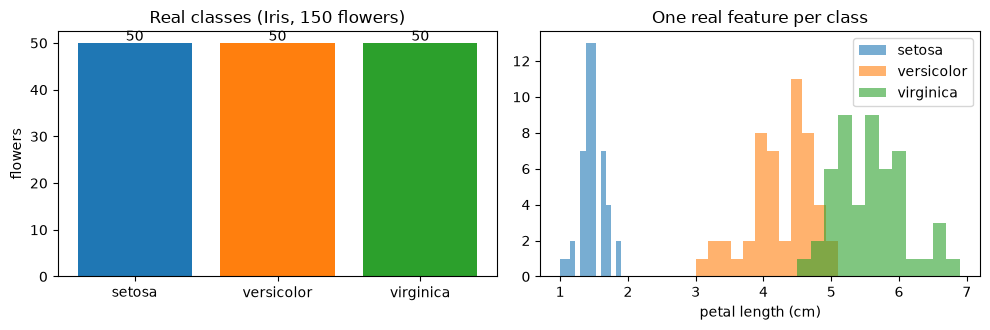

In [5]:
print("shape:", df[FEATURES].shape)
print("feature names:", FEATURES)
print("original label values:", dict(enumerate(CLASS_NAMES)))
print("class counts (all):\n", df["species"].value_counts().to_string())
print("class counts train:", dict(zip(*np.unique(y_all[idx_train], return_counts=True))),
      "| test:", dict(zip(*np.unique(y_all[idx_test], return_counts=True))))
display(df.groupby("species")[FEATURES].agg(["min", "max"]).round(2))

COLORS = ["tab:blue", "tab:orange", "tab:green"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
counts = df["species"].value_counts().reindex(CLASS_NAMES)
ax[0].bar(CLASS_NAMES, counts.values, color=COLORS)
ax[0].set_title("Real classes (Iris, 150 flowers)"); ax[0].set_ylabel("flowers")
for i, v in enumerate(counts.values): ax[0].text(i, v + 0.5, str(v), ha="center")
for k, name in enumerate(CLASS_NAMES):
    ax[1].hist(X_raw[y_all == k, 2], bins=12, alpha=0.6, color=COLORS[k], label=name)
ax[1].set_xlabel("petal length (cm)"); ax[1].set_title("One real feature per class"); ax[1].legend()
plt.tight_layout(); plt.show()

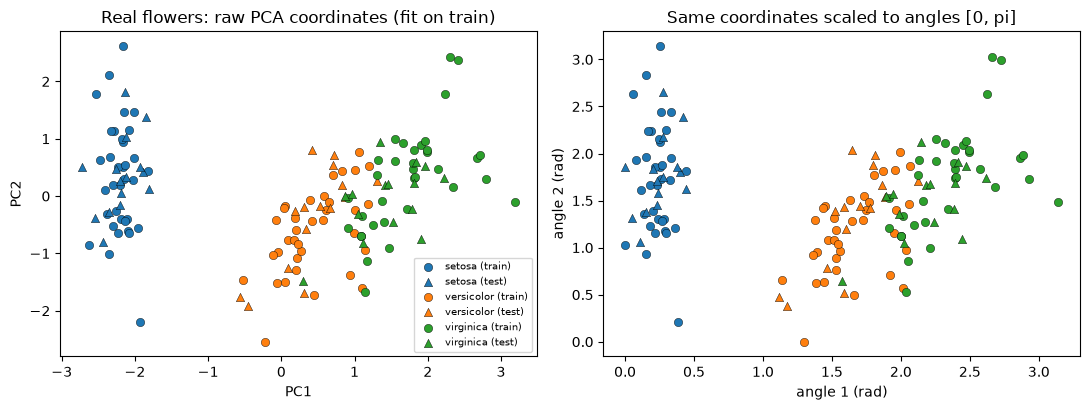

explained variance of the two components: [0.726 0.234]


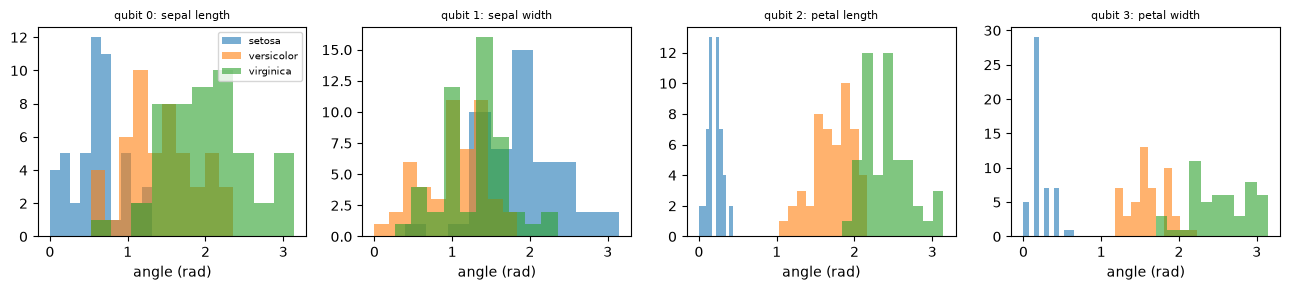

In [6]:
# 2-D scatter of the real observations coloured by their true species.
# (a) raw PCA coordinates (StandardScaler -> PCA(2), both fitted on the training split)
# (b) the same two coordinates scaled to [0, pi] (MinMax fitted on the training split, test clipped) = the angle range used by the encoder
std_vis = StandardScaler().fit(X_raw[idx_train]); pca_vis = PCA(n_components=2, random_state=SEED).fit(std_vis.transform(X_raw[idx_train]))
Z_pca = pca_vis.transform(std_vis.transform(X_raw))
mm_vis = MinMaxScaler((0, np.pi)).fit(Z_pca[idx_train]); Z_ang = np.clip(mm_vis.transform(Z_pca), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for k, name in enumerate(CLASS_NAMES):
    for split, marker in ((idx_train, "o"), (idx_test, "^")):
        m = y_all[split] == k
        ax[0].scatter(Z_pca[split][m, 0], Z_pca[split][m, 1], c=COLORS[k], marker=marker, edgecolor="k", linewidth=0.3, label=f"{name} ({'train' if marker=='o' else 'test'})")
        ax[1].scatter(Z_ang[split][m, 0], Z_ang[split][m, 1], c=COLORS[k], marker=marker, edgecolor="k", linewidth=0.3)
ax[0].set_title("Real flowers: raw PCA coordinates (fit on train)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)
ax[1].set_title("Same coordinates scaled to angles [0, pi]"); ax[1].set_xlabel("angle 1 (rad)"); ax[1].set_ylabel("angle 2 (rad)")
plt.tight_layout(); plt.show()
print("explained variance of the two components:", pca_vis.explained_variance_ratio_.round(3))

# the 4 angles that the encoder really uses (one per qubit), per species
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for j in range(4):
    for k, name in enumerate(CLASS_NAMES):
        ax[j].hist(X_ang[y_all == k, j], bins=10, alpha=0.6, color=COLORS[k], label=name)
    ax[j].set_title(f"qubit {j}: {FEATURES[j].replace(' (cm)', '')}", fontsize=8); ax[j].set_xlabel("angle (rad)")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 2. Algorithm 1 (DLA basis), the adjoint representation and the victim models

Generators are Pauli strings, so $e^{-i\theta H}$ is a `PauliRot(2*theta)` in PennyLane. We build the DLA with the commutator closure, store it as an orthonormal set of Hermitian matrices $B_\alpha$
(`<A,B> = Tr(AB)/2^n`), and represent each generator by its adjoint matrix $T_H$, $(T_H)_{\alpha\beta}=\langle B_\alpha, i[H,B_\beta]\rangle$. Then $U_k^\dagger K U_k=e^{\theta_kT_k}K$ on coefficient vectors,
and the coefficient vector of the Heisenberg-evolved observable is $c(\theta)=M_1\cdots M_D\,\mu$ with $M_k=e^{\theta_kT_{\nu(k)}}$. The model output is $y=c(\theta)\cdot e_{\rm snap}$ and the gradient
$C_k=\chi^{(k)}\cdot e_{\rm snap}$ with $\chi^{(k)}=M_1\cdots M_{k-1}\,T_{\nu(k)}\,M_k\cdots M_D\,\mu$ (Eqs. 17 to 23 of the paper).

In [7]:
PAULI = {"I": np.eye(2, dtype=complex), "X": np.array([[0, 1], [1, 0]], complex),
         "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0, -1.0]).astype(complex)}

def pauli_op(n, d):
    # Pauli string as a 2^n x 2^n matrix; d maps wire -> 'X'|'Y'|'Z'
    s = ["I"] * n
    for q, p in d.items(): s[q] = p
    out = np.array([[1.0 + 0j]])
    for c in s: out = np.kron(out, PAULI[c])
    return out

def ip(a, b):
    # CHOICE: normalised Frobenius inner product Tr(AB)/2^n for Hermitian A, B
    return np.real(np.vdot(a, b)) / a.shape[0]

def coeffs(B, h):
    # coordinates of a Hermitian matrix h in the orthonormal basis B (array dim x 2^n x 2^n)
    return np.real(np.conj(B.reshape(len(B), -1)) @ h.ravel()) / h.shape[0]

def find_dla(gens, tol=1e-9):
    # Algorithm 1: closure under commutators. CHOICE: only commutators of new elements with the generators are formed
    # (nested commutators [H_a,[H_b,...]] already span the whole Lie closure).
    D = gens[0].shape[0]
    rows = []
    def reduce(h):
        h = h.copy()
        for _ in range(2):                          # two Gram-Schmidt passes for numerical stability
            if rows:
                Bm = np.array([r.ravel() for r in rows])
                c = np.real(np.conj(Bm) @ h.ravel()) / D
                h = h - (c @ Bm).reshape(D, D)
        return h
    frontier = []
    for g in gens:
        h = reduce(g); nm = np.sqrt(ip(h, h))
        if nm > tol: rows.append(h / nm); frontier.append(h / nm)
    while frontier:
        new = []
        for a in frontier:
            for g in gens:
                h = reduce(1j * (a @ g - g @ a)); nm = np.sqrt(ip(h, h))
                if nm > tol: rows.append(h / nm); new.append(h / nm)
        frontier = new
    return np.array(rows)

def ad_matrix(B, H):
    # (T_H)_{ab} = <B_a, i[H, B_b]>  (real antisymmetric), plus the closure residual (must be ~0 for H in the DLA)
    comm = [1j * (H @ b - b @ H) for b in B]
    T = np.array([coeffs(B, c) for c in comm]).T
    res = max(np.linalg.norm(c - (coeffs(B, c) @ B.reshape(len(B), -1)).reshape(H.shape)) for c in comm)
    return T, res

def word_of(d):
    return "".join(d[w] for w in sorted(d)), sorted(d)

class VQCModel:
    # n qubits, Pauli-product encoding RX(x_j)|0>, ansatz = `layers` repetitions of the generator list (one parameter per generator and layer)
    def __init__(self, name, n, gens_spec, layers, obs_spec):
        self.name, self.n, self.layers = name, n, layers
        self.gens_spec, self.obs_spec = gens_spec, obs_spec
        self.gens = [pauli_op(n, d) for d in gens_spec]
        self.N = len(gens_spec); self.D = self.N * layers
        self.B = find_dla(self.gens)                       # Algorithm 1
        self.dim = len(self.B)
        TT = [ad_matrix(self.B, H) for H in self.gens]
        self.T = [t for t, _ in TT]; self.closure_residual = max(r for _, r in TT)
        self.O = sum(c * pauli_op(n, d) for c, d in obs_spec)
        self.mu = coeffs(self.B, self.O)
        self.lasa_residual = np.linalg.norm(self.O - (self.mu @ self.B.reshape(self.dim, -1)).reshape(self.O.shape))
        self.words = [word_of(d) for d in gens_spec]
        self._qnode = None

    def with_layers(self, layers):
        m = object.__new__(VQCModel); m.__dict__.update(self.__dict__); m.layers = layers; m.D = self.N * layers; m._qnode = None
        return m

    def chi(self, theta):
        # g-sim: returns A (D x dim) with A[k] = chi^(k), and c(theta) (the evolved observable); y = c . e, C = A e
        T, mu, D, N = self.T, self.mu, self.D, self.N
        M = [expm(theta[k] * T[k % N]) for k in range(D)]
        R = [None] * (D + 1); R[D] = mu
        for k in range(D - 1, -1, -1): R[k] = M[k] @ R[k + 1]
        A = np.zeros((D, self.dim)); Lp = np.eye(self.dim)
        for k in range(D):
            A[k] = Lp @ (T[k % N] @ R[k]); Lp = Lp @ M[k]
        return A, R[0]

    def snapshot(self, x):
        # exact snapshot e_alpha = <psi(x)|B_alpha|psi(x)> for the product state prod_j RX(x_j)|0>, x of shape (Ns, n) or (n,)
        x = np.atleast_2d(x)
        out = []
        for xi in x:
            psi = np.array([1.0 + 0j])
            for xj in xi: psi = np.kron(psi, np.array([np.cos(xj / 2), -1j * np.sin(xj / 2)]))
            out.append(np.real(np.einsum("i,bij,j->b", psi.conj(), self.B, psi)))
        return np.array(out)

    def qnode(self):
        # the circuit that is actually executed (victim model), PennyLane, exact simulator
        if self._qnode is None:
            n, L, words = self.n, self.layers, self.words
            if len(self.obs_spec) == 1 and len(self.obs_spec[0][1]) == 1:
                (c, d), = self.obs_spec; (w, p), = d.items()
                obs = {"X": qml.PauliX, "Y": qml.PauliY, "Z": qml.PauliZ}[p](w)
            else:
                obs = qml.sum(*[ {"X": qml.PauliX, "Y": qml.PauliY, "Z": qml.PauliZ}[p](w) for c, d in self.obs_spec for w, p in d.items()])
            dev = qml.device("default.qubit", wires=n)
            @qml.qnode(dev, interface="autograd", diff_method="backprop")
            def circuit(x, theta):
                for j in range(n): qml.RX(x[..., j], wires=j)
                k = 0
                for _ in range(L):
                    for word, wires in words:
                        qml.PauliRot(2 * theta[..., k], word, wires=wires); k += 1
                return qml.expval(obs)
            self._qnode = circuit
        return self._qnode

    def victim_gradients(self, X, theta):
        # gradients dy/dtheta_j of the executed circuit for every row of X (what the client would send)
        # one backward pass: theta is tiled over the batch, so d(sum_i y_i)/d theta_i = per-sample gradient
        qn = self.qnode(); Xp = pnp.array(np.atleast_2d(X), requires_grad=False)
        th_t = pnp.array(np.tile(np.asarray(theta, float), (len(Xp), 1)), requires_grad=True)
        return np.array(qml.grad(lambda x, th: pnp.sum(qn(x, th)), argnums=1)(Xp, th_t))

    def victim_output(self, X, theta):
        return np.array(self.qnode()(pnp.array(X, requires_grad=False), pnp.array(theta, requires_grad=False)))

def chain(n, w): return [{j: w[0], j + 1: w[1]} for j in range(n - 1)]
def single(n, p): return [{j: p} for j in range(n)]

def make_models(n):
    return {
        # compound ansatz (ref. 36 of the paper): independent single-qubit rotations, DLA = su(2)^n, dim 3n
        "compound": VQCModel("compound", n, single(n, "X") + single(n, "Z"), 2, [(1.0, {j: "Z"}) for j in range(n)]),
        # free-fermion (matchgate) ansatz XX, YY, Z: DLA = so(2n), dim n(2n-1); iZ_j in g for every j
        "xy_free": VQCModel("xy_free", n, chain(n, "XX") + chain(n, "YY") + single(n, "Z"), 4, [(1.0, {0: "Z"})]),
        # transverse-field Ising with boundary fields: DLA = so(2n+2); only the two end qubits have iZ_j in g
        "tfim_bf": VQCModel("tfim_bf", n, single(n, "X") + chain(n, "ZZ") + [{0: "Z"}, {n - 1: "Z"}], 6, [(1.0, {0: "Z"})]),
    }

t0 = time.time()
MODELS = make_models(N_QUBITS)
rows = []
for k, m in MODELS.items():
    rows.append(dict(model=k, qubits=m.n, generators=m.N, layers=m.layers, parameters_D=m.D, dim_DLA=m.dim,
                     closure_residual=f"{m.closure_residual:.1e}", LASA_residual=f"{m.lasa_residual:.1e}",
                     D_ge_dim=m.D >= m.dim))
print(f"Algorithm 1 for the three victim models ({time.time()-t0:.1f} s)")
display(pd.DataFrame(rows))
assert all(m.lasa_residual < 1e-9 and m.closure_residual < 1e-9 for m in MODELS.values())

Algorithm 1 for the three victim models (2.6 s)


,model,qubits,generators,layers,parameters_D,dim_DLA,closure_residual,LASA_residual,D_ge_dim
0,compound,4,8,2,16,12,0.0e+00,0.0e+00,True
1,xy_free,4,10,4,40,28,0.0e+00,0.0e+00,True
2,tfim_bf,4,9,6,54,45,0.0e+00,0.0e+00,True


### DLA dimension versus the number of qubits

Theory: a polynomial DLA is what makes a VQC trainable (no barren plateau) *and* what makes its snapshot recoverable; an exponential DLA ($\dim\mathfrak g=4^n-1$ for a universal ansatz) is the only protection. We run Algorithm 1 for growing $n$.

family,compound,tfim_bf,universal,xy_free
n,,,,
2,6.0,15.0,15.0,6.0
3,9.0,28.0,63.0,15.0
4,12.0,45.0,255.0,28.0
5,15.0,66.0,NaN,45.0


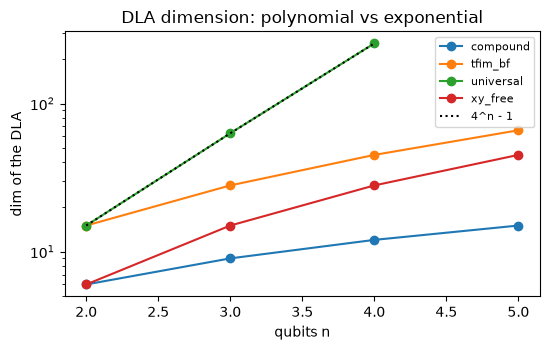

closed forms found: compound 3n, xy_free n(2n-1), tfim_bf (n+1)(2n+1) -> exact: {'compound': True, 'tfim_bf': True, 'xy_free': True}
universal family dim == 4^n - 1: True | log-log growth exponents of the polynomial families: {'compound': 1.0, 'tfim_bf': 1.61, 'xy_free': 2.2}


In [8]:
def dla_family(name, n):
    if name == "compound": gens = single(n, "X") + single(n, "Z")
    elif name == "xy_free": gens = chain(n, "XX") + chain(n, "YY") + single(n, "Z")
    elif name == "tfim_bf": gens = single(n, "X") + chain(n, "ZZ") + [{0: "Z"}, {n - 1: "Z"}]
    elif name == "universal": gens = single(n, "X") + single(n, "Z") + chain(n, "ZZ")
    return gens

rows = []
for name in ["compound", "xy_free", "tfim_bf", "universal"]:
    nmax = DLA_NMAX_UNIV if name == "universal" else DLA_NMAX_POLY
    for n in range(2, nmax + 1):
        t0 = time.time(); B = find_dla([pauli_op(n, d) for d in dla_family(name, n)])
        rows.append(dict(family=name, n=n, dim_DLA=len(B), seconds=round(time.time() - t0, 1)))
dla_df = pd.DataFrame(rows)
display(dla_df.pivot(index="n", columns="family", values="dim_DLA"))
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for name, g in dla_df.groupby("family"):
    ax.plot(g["n"], g["dim_DLA"], "o-", label=name)
nn = np.arange(2, DLA_NMAX_POLY + 1)
ax.plot(np.arange(2, DLA_NMAX_UNIV + 1), 4.0 ** np.arange(2, DLA_NMAX_UNIV + 1) - 1, "k:", label="4^n - 1")
ax.set_yscale("log"); ax.set_xlabel("qubits n"); ax.set_ylabel("dim of the DLA"); ax.set_title("DLA dimension: polynomial vs exponential"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
# claims: universal family has dimension 4^n - 1; polynomial families grow like n^2 (log-log slope close to 2)
univ = dla_df[dla_df.family == "universal"]
RES["univ_exact"] = bool(((4 ** univ.n - 1) == univ.dim_DLA).all())
form = {"compound": lambda n: 3 * n, "xy_free": lambda n: n * (2 * n - 1), "tfim_bf": lambda n: (n + 1) * (2 * n + 1)}
RES["poly_exact"] = {nm: bool((g.dim_DLA == g.n.map(form[nm])).all()) for nm, g in dla_df[dla_df.family != "universal"].groupby("family")}
RES["poly_slopes"] = {nm: float(np.polyfit(np.log(g.n), np.log(g.dim_DLA), 1)[0]) for nm, g in dla_df[dla_df.family != "universal"].groupby("family")}
print("closed forms found: compound 3n, xy_free n(2n-1), tfim_bf (n+1)(2n+1) -> exact:", RES["poly_exact"])
print("universal family dim == 4^n - 1:", RES["univ_exact"], "| log-log growth exponents of the polynomial families:", {k: round(v, 2) for k, v in RES["poly_slopes"].items()})

## Quantum Circuit Architecture

The victim circuits below are exactly the PennyLane QNodes that produce the gradients the attacker sees (exact `default.qubit` simulator, `RX(x_j)` data encoding on every qubit,
then `PauliRot(2*theta_k)` gates that implement $e^{-i\theta_kP_k}$, then the measurement). Each drawing is produced from the real QNode, the printed qubit count, depth and trainable-parameter count come from
`qml.specs`, and a cell asserts that the circuit's output and its full gradient equal the Lie-algebraic simulator (so the drawn circuit *is* the model that g-sim describes). Assumptions where the paper gives no circuit: the
generator sets, the layer counts and the observables are our choices (table in Section 2); the encoding is the paper's Eq. (26) Pauli-product map.

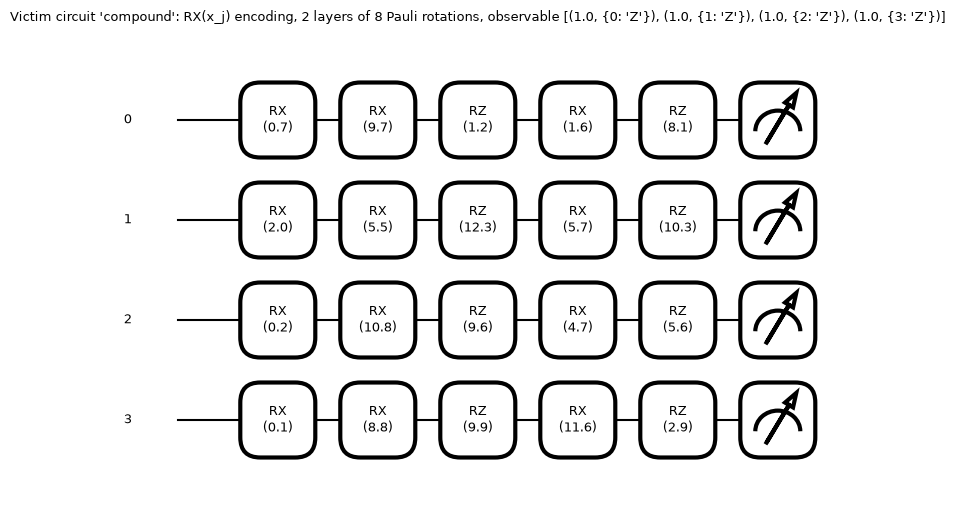

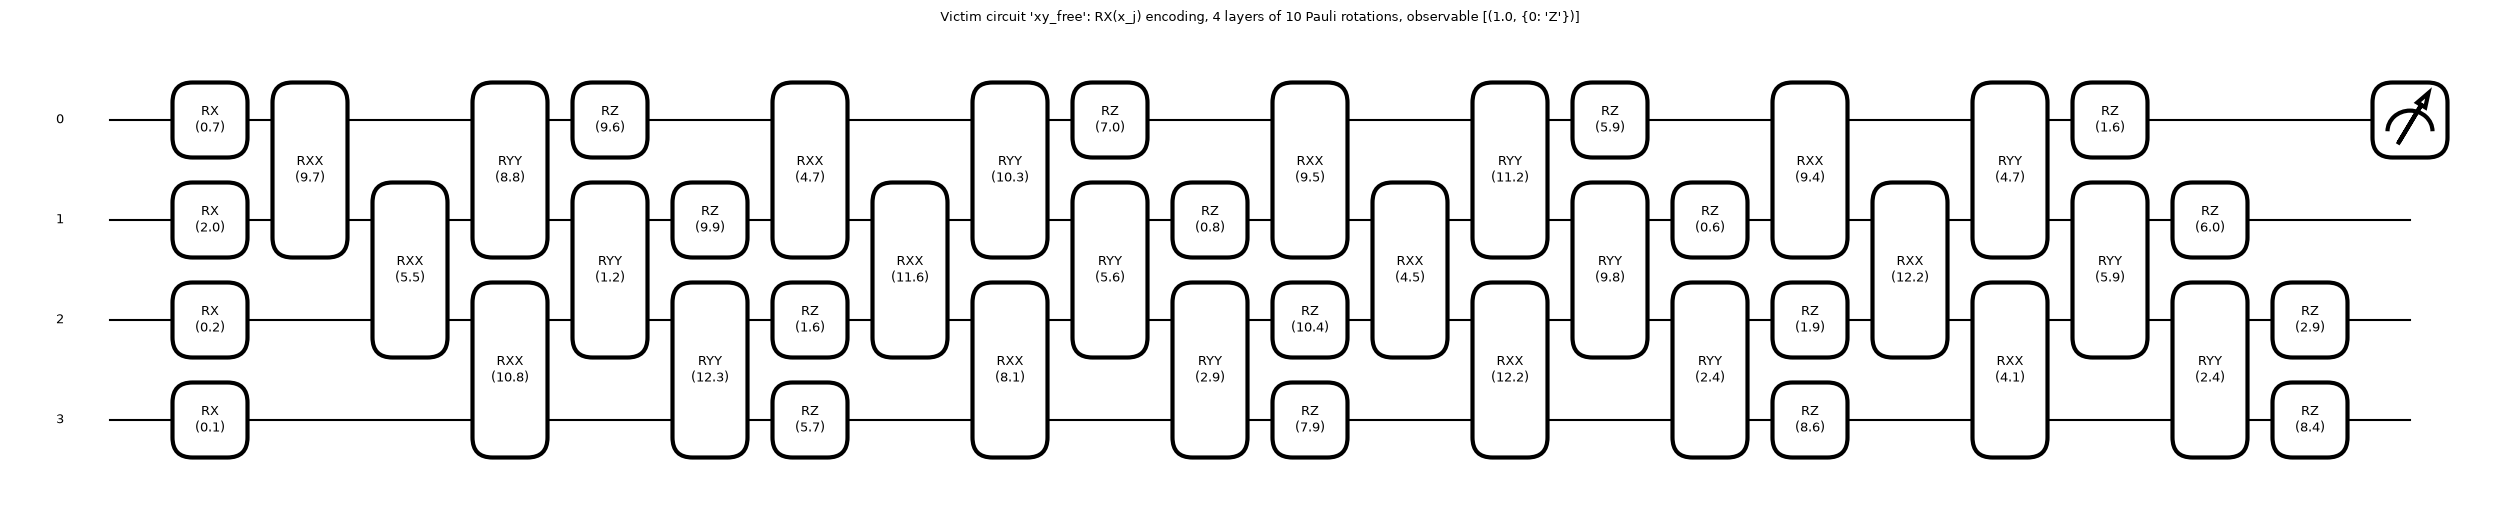

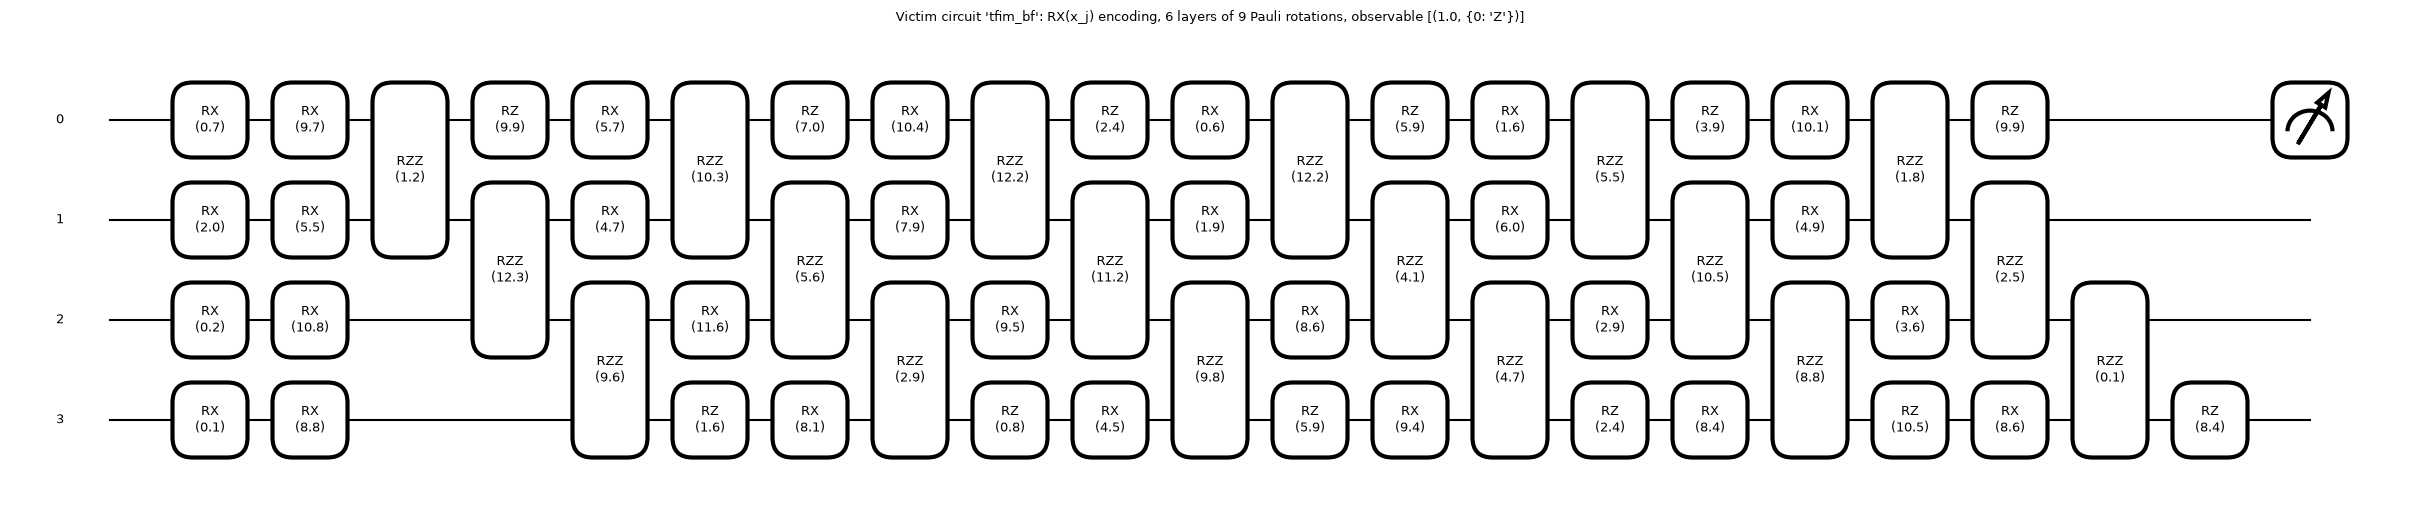

,model,qubits,depth,gates,trainable_parameters,data_inputs
0,compound,4,5,20,16,4
1,xy_free,4,22,44,40,4
2,tfim_bf,4,21,58,54,4


In [9]:
def circuit_stats(model, x0, th0):
    sp = qml.specs(model.qnode())(x0, th0)
    return dict(qubits=model.n, depth=sp["resources"].depth, gates=sp["resources"].num_gates, trainable_parameters=model.D, data_inputs=model.n)

x0 = pnp.array(X_ang[0], requires_grad=False)
rows = []
for name, m in MODELS.items():
    th0 = pnp.array(np.random.default_rng(SEED).uniform(0, 2 * np.pi, m.D), requires_grad=True)
    fig, ax = qml.draw_mpl(m.qnode(), decimals=1, fontsize=9)(x0, th0)
    fig.suptitle(f"Victim circuit '{name}': RX(x_j) encoding, {m.layers} layers of {m.N} Pauli rotations, observable {m.obs_spec}", fontsize=9, y=1.02)
    plt.show()
    rows.append(dict(model=name, **circuit_stats(m, x0, th0)))
display(pd.DataFrame(rows))

In [10]:
# Assertion: the drawn/executed QNode == g-sim (output y and the whole gradient vector), for every model and several Iris inputs
rows = []
for name, m in MODELS.items():
    th = np.random.default_rng(SEED + 1).uniform(0, 2 * np.pi, m.D)
    A, c = m.chi(th)
    Xs = X_ang[[0, 50, 100, 149]]
    e = m.snapshot(Xs)
    y_q, g_q = m.victim_output(Xs, th), m.victim_gradients(Xs, th)
    dy, dg = np.abs(y_q - e @ c).max(), np.abs(g_q - e @ A.T).max()
    rows.append(dict(model=name, max_abs_diff_output=f"{dy:.1e}", max_abs_diff_gradients=f"{dg:.1e}"))
    assert dy < 1e-9 and dg < 1e-9, (name, dy, dg)
display(pd.DataFrame(rows))
RES["gsim_vs_qnode"] = max(float(r["max_abs_diff_gradients"]) for r in rows)
print("OK: g-sim reproduces the executed PennyLane circuits (output and gradients).")

,model,max_abs_diff_output,max_abs_diff_gradients
0,compound,8.3e-14,2.2e-13
1,xy_free,5.3e-14,2.8e-13
2,tfim_bf,5.6e-14,2.1e-13


OK: g-sim reproduces the executed PennyLane circuits (output and gradients).


## 3. Algorithm 2: snapshot recovery (weak privacy breach)

Given the gradient vector $C\in\mathbb R^D$ of one sample at known $\theta$, build $A$ ($A_{jk}=\chi^{(j)}_k$) and solve $C=A\,e_{\rm snap}$ (Eq. 24).

**A caveat the paper does not discuss.** Every row of $A$ is a tangent vector of the *adjoint orbit* of $O$ at $c(\theta)$ (it is $\partial c/\partial\theta_j$). So $\operatorname{rank}A\le\dim(\text{orbit})<\dim\mathfrak g$ even when $D\gg\dim\mathfrak g$: a single gradient vector
determines only part of the snapshot (the part along $c(\theta)$ itself is never determined, and for $O=Z_1$ in $\mathfrak{so}(2n)$ the orbit is much smaller than $\mathfrak g$). The remedy that stays within the paper's threat model is to
use the gradients of several training rounds $\theta_1,\dots,\theta_R$ computed on the same private input: stacking the systems fills the rank. The cell below measures $\operatorname{rank}A$ for one round and the number of rounds $R$ needed.

In [11]:
def stacked_system(model, thetas):
    return np.vstack([model.chi(th)[0] for th in thetas])

def rank_of(A, rtol=1e-8):
    s = np.linalg.svd(A, compute_uv=False)
    return int((s > rtol * s[0]).sum()), s

def draw_thetas(model, seed, rounds):
    r = np.random.default_rng(seed)
    return [r.uniform(0, 2 * np.pi, model.D) for _ in range(rounds)]

def rounds_needed(model, seed):
    th_all = draw_thetas(model, seed, ROUNDS_MAX)
    for R in range(1, ROUNDS_MAX + 1):
        rk, _ = rank_of(stacked_system(model, th_all[:R]))
        if rk == model.dim: return R, th_all[:R]
    return None, th_all

rows = []
for name, m in MODELS.items():
    rk1 = [rank_of(m.chi(draw_thetas(m, SEED + s, 1)[0])[0])[0] for s in range(N_THETA_SEEDS)]
    Rn = [rounds_needed(m, SEED + s)[0] for s in range(N_THETA_SEEDS)]
    rows.append(dict(model=name, dim_DLA=m.dim, D=m.D, rank_A_one_round=int(np.mean(rk1)), rounds_for_full_rank=max(r for r in Rn if r) if all(Rn) else None,
                     equations_needed=(max(r for r in Rn if r) * m.D) if all(Rn) else None))
rank_df = pd.DataFrame(rows); display(rank_df)
RES["rank_df"] = rank_df

,model,dim_DLA,D,rank_A_one_round,rounds_for_full_rank,equations_needed
0,compound,12,16,8,2,32
1,xy_free,28,40,12,4,160
2,tfim_bf,45,54,16,5,270


## 4. Algorithm 3: classical snapshot inversion for the Pauli-product encoding (strong privacy breach)

For $\rho(x)=\bigotimes_j R_X(x_j)|0\rangle\langle0|R_X(-x_j)$ we have $\langle Z_j\rangle=\cos x_j$ and $\langle Y_j\rangle=-\sin x_j$. The algorithm needs to express $Z_j$ (or a mix $\alpha Z_j+\beta Y_j$) inside the DLA:

* if $iZ_j\in\mathfrak g$: $x_j=\arccos\langle Z_j\rangle=\arccos\sum_k\gamma_k[e_{\rm snap}]_k$ with $Z_j=\sum_k\gamma_kB_k$ (Eq. 30);
* else if $iY_j\in\mathfrak g$: same with $Y_j$ (phase shift $\pi/2$);
* else: write the DLA basis in the Pauli basis, form the $2\times\dim\mathfrak g$ matrix $A^TC$ that projects $\{Z_j,Y_j\}$ onto $\mathfrak g$ and take its SVD; a singular value equal to 1 means a combination $W=\alpha Z_j+\beta Y_j$ lies in $\mathfrak g$ and
  $x_j=\arccos\big(\mathrm{sign}(\alpha)\langle W\rangle/\sqrt{\alpha^2+\beta^2}\big)-\arctan(\beta/\alpha)$ (Eq. 29); otherwise the algorithm returns FAILURE.

The result is defined up to the periodicity of the trigonometric functions; our Iris angles lie in $[0,\pi]$ so the principal branch of $\arccos$ is the right one.

In [12]:
_PAULI_CACHE = {}
def all_paulis(n):
    if n not in _PAULI_CACHE:
        import itertools
        words = ["".join(w) for w in itertools.product("IXYZ", repeat=n)]
        mats = np.array([pauli_op(n, {q: c for q, c in enumerate(w) if c != "I"}) for w in words])
        _PAULI_CACHE[n] = (words, mats)
    return _PAULI_CACHE[n]

def inversion_plan(model, j, tol=1e-6):
    # Precompute everything Algorithm 3 needs for qubit j (it depends only on the DLA, not on the data)
    n, B = model.n, model.B
    Zj, Yj = pauli_op(n, {j: "Z"}), pauli_op(n, {j: "Y"})
    gZ, gY = coeffs(B, Zj), coeffs(B, Yj)
    inZ = np.linalg.norm(Zj - (gZ @ B.reshape(len(B), -1)).reshape(Zj.shape)) < 1e-9
    inY = np.linalg.norm(Yj - (gY @ B.reshape(len(B), -1)).reshape(Yj.shape)) < 1e-9
    if inZ: return dict(branch="iZ_j in g", gamma=gZ, alpha=1.0, beta=0.0)
    if inY: return dict(branch="iY_j in g", gamma=gY, alpha=0.0, beta=1.0)
    words, mats = all_paulis(n)
    C0 = np.real(np.einsum("pij,kji->kp", mats, B)) / (2 ** n)           # components of every B_k on every Pauli string
    support = np.where(np.abs(C0).max(axis=0) > 1e-12)[0]
    iz, iy = words.index("I" * j + "Z" + "I" * (n - j - 1)), words.index("I" * j + "Y" + "I" * (n - j - 1))
    Pg = sorted(set(support) | {iz, iy})
    C = C0[:, Pg].T                                                       # |Pg| x dim
    Amat = np.zeros((len(Pg), 2)); Amat[Pg.index(iz), 0] = 1; Amat[Pg.index(iy), 1] = 1
    U, s, Vt = np.linalg.svd(Amat.T @ C, full_matrices=False)
    hit = np.where(np.abs(s - 1) < tol)[0]
    if len(hit) == 0: return dict(branch="FAILURE", singular_values=s)
    a, b = U[:, hit[0]]
    return dict(branch="SVD", gamma=a * gZ + b * gY, alpha=float(a), beta=float(b), singular_values=s)

def invert_snapshot(plan, e):
    # e: (Ns, dim) snapshots -> x_j (Ns,) or None on FAILURE
    if plan["branch"] == "FAILURE": return None
    a, b, val = plan["alpha"], plan["beta"], e @ plan["gamma"]
    if a < 0 or (a == 0 and b < 0): a, b, val = -a, -b, -val
    R = np.hypot(a, b)
    return np.arccos(np.clip(val / R, -1, 1)) - np.arctan2(b, a)

PLANS = {name: [inversion_plan(m, j) for j in range(m.n)] for name, m in MODELS.items()}
display(pd.DataFrame({name: [p["branch"] for p in pl] for name, pl in PLANS.items()}, index=[f"qubit {j}" for j in range(N_QUBITS)]))

# Unit test of the SVD branch (Eq. 29): abelian ansatz with generators G_j = (Z_j + Y_j)/sqrt(2); iZ_j and iY_j are NOT in g but G_j is.
nt = 2
Gs = [(pauli_op(nt, {j: "Z"}) + pauli_op(nt, {j: "Y"})) / np.sqrt(2) for j in range(nt)]
class _Toy: pass
toy = _Toy(); toy.n = nt; toy.B = find_dla(Gs)
toy_plans = [inversion_plan(toy, j) for j in range(nt)]
xs_test = np.array([[0.3, 1.1], [0.9, 0.2], [1.4, 0.7]])
def _snap(Bm, x):
    out = []
    for xi in np.atleast_2d(x):
        psi = np.array([1.0 + 0j])
        for xj in xi: psi = np.kron(psi, np.array([np.cos(xj / 2), -1j * np.sin(xj / 2)]))
        out.append(np.real(np.einsum("i,bij,j->b", psi.conj(), Bm, psi)))
    return np.array(out)
e_toy = _snap(toy.B, xs_test)
rec = np.array([invert_snapshot(toy_plans[j], e_toy) for j in range(nt)]).T
print("toy SVD branch:", [p["branch"] for p in toy_plans], "| alpha,beta =", [(round(p['alpha'], 3), round(p['beta'], 3)) for p in toy_plans])
print("true angles:\n", xs_test, "\nrecovered:\n", rec.round(6))
assert np.abs(rec - xs_test).max() < 1e-6
RES["svd_branch_ok"] = True

,compound,xy_free,tfim_bf
qubit 0,iZ_j in g,iZ_j in g,iZ_j in g
qubit 1,iZ_j in g,iZ_j in g,FAILURE
qubit 2,iZ_j in g,iZ_j in g,FAILURE
qubit 3,iZ_j in g,iZ_j in g,iZ_j in g


toy SVD branch: ['SVD', 'SVD'] | alpha,beta = [(-0.707, -0.707), (0.707, 0.707)]
true angles:
 [[0.3 1.1]
 [0.9 0.2]
 [1.4 0.7]] 
recovered:
 [[0.3 1.1]
 [0.9 0.2]
 [1.4 0.7]]


## 5. End-to-end attack on the Iris flowers

For every flower the *client* computes the gradient of its VQC output with the real PennyLane circuit (Section "Quantum Circuit Architecture"), for $R$ training rounds with parameters $\theta_1..\theta_R$ that the attacker knows.
The *attacker* only gets the gradients, the architecture, the observable and $\theta$. He (1) solves the stacked linear system (Algorithm 2, min-norm least squares) and (2) inverts the snapshot (Algorithm 3).
We compare $R=1$ (the paper's single system) with $R=R_{\rm needed}$ (full rank), and with the trivial baseline "answer the training mean". Metrics over the 150 flowers, mean ± std over `N_THETA_SEEDS` draws of $\theta$.

In [13]:
def solve_snapshot(A, G):
    # min-norm least squares for all samples at once: G is (Ns, equations)
    sol = np.linalg.lstsq(A, G.T, rcond=1e-10)[0]
    return sol.T

def attack_model(model, plans, X, seed, rounds, thetas=None):
    # client side: real circuit gradients; attacker side: Algorithms 2 and 3
    thetas = thetas if thetas is not None else draw_thetas(model, seed, rounds)
    t0 = time.time()
    G = np.hstack([model.victim_gradients(X, th) for th in thetas])           # (Ns, R*D)  <- what the attacker receives
    t_client = time.time() - t0
    t0 = time.time()
    A = stacked_system(model, thetas)
    e_rec = solve_snapshot(A, G)                                              # Algorithm 2
    x_rec = np.full(X.shape, np.nan)
    for j, pl in enumerate(plans):
        r = invert_snapshot(pl, e_rec)                                        # Algorithm 3
        if r is not None: x_rec[:, j] = r
    t_attack = time.time() - t0
    return dict(e_rec=e_rec, x_rec=x_rec, G=G, A=A, rank=rank_of(A)[0], t_client=t_client, t_attack=t_attack, thetas=thetas)

def summarise(model, out, X, e_true):
    snap_err = np.abs(out["e_rec"] - e_true).max(axis=1)                      # Definition 6: max over components
    ang_err = np.abs(out["x_rec"] - X)
    ok_cols = ~np.isnan(out["x_rec"]).any(axis=0)
    return dict(rank=out["rank"], snap_err_median=float(np.median(snap_err)), snap_ok=float((snap_err < EPS_SNAP).mean()),
                angle_MAE=float(np.nanmean(ang_err[:, ok_cols])) if ok_cols.any() else np.nan,
                angle_ok=float((ang_err[:, ok_cols] < EPS_ANGLE).mean()) if ok_cols.any() else np.nan,
                failure_qubits=[j for j in range(model.n) if not ok_cols[j]],
                per_qubit_MAE=[float(np.nanmean(ang_err[:, j])) if ok_cols[j] else np.nan for j in range(model.n)])

E_TRUE = {name: m.snapshot(X_ang) for name, m in MODELS.items()}
baseline_mae = float(np.abs(X_ang[idx_test] - X_ang[idx_train].mean(axis=0)).mean())
print(f"baseline 'answer the training mean': mean absolute angle error on the test flowers = {baseline_mae:.3f} rad")

ATTACK = {}      # (model, 'R1' | 'Rfull', seed) -> output/summary
rows = []
for name, m in MODELS.items():
    for s in range(N_THETA_SEEDS):
        seed = SEED + s
        R, thetas_full = rounds_needed(m, seed)
        assert R is not None, (name, "full rank not reached")
        out_full = attack_model(m, PLANS[name], X_ang, seed, R, thetas_full[:R])
        out_one = attack_model(m, PLANS[name], X_ang, seed, 1, thetas_full[:1])
        for tag, out in (("R=1", out_one), (f"R={R}", out_full)):
            sm = summarise(m, out, X_ang, E_TRUE[name])
            ATTACK[(name, tag if tag == "R=1" else "Rfull", s)] = (out, sm)
            rows.append(dict(model=name, seed=seed, rounds=tag, equations=out["A"].shape[0], rank=sm["rank"], dim_DLA=m.dim,
                             snapshot_err_median=sm["snap_err_median"], snapshot_ok_frac=sm["snap_ok"], angle_MAE=sm["angle_MAE"],
                             angle_ok_frac=sm["angle_ok"], FAILURE_qubits=sm["failure_qubits"], t_client_s=out["t_client"], t_attack_s=out["t_attack"]))
att_df = pd.DataFrame(rows)
att_df["rounds_kind"] = np.where(att_df.rounds == "R=1", "one round (paper's single system)", "full-rank stack")
display(att_df.groupby(["model", "rounds_kind"]).agg(equations=("equations", "mean"), rank=("rank", "mean"), dim_DLA=("dim_DLA", "first"),
        snapshot_err_median=("snapshot_err_median", "mean"), snapshot_ok_frac=("snapshot_ok_frac", "mean"),
        angle_MAE_mean=("angle_MAE", "mean"), angle_MAE_std=("angle_MAE", "std"), angle_ok_frac=("angle_ok_frac", "mean"),
        t_client_s=("t_client_s", "mean"), t_attack_s=("t_attack_s", "mean")).round(6))
print("FAILURE qubits (Algorithm 3 returns FAILURE, per model):", {name: PLANS[name][0]['branch'] and [j for j, p in enumerate(PLANS[name]) if p['branch'] == 'FAILURE'] for name in MODELS})

baseline 'answer the training mean': mean absolute angle error on the test flowers = 0.654 rad


equations  rank  dim_DLA  \
model    rounds_kind                                                   
compound full-rank stack                         32.0  12.0       12   
         one round (paper's single system)       16.0   8.0       12   
tfim_bf  full-rank stack                        270.0  45.0       45   
         one round (paper's single system)       54.0  16.0       45   
xy_free  full-rank stack                        160.0  28.0       28   
         one round (paper's single system)       40.0  12.0       28   

                                            snapshot_err_median  \
model    rounds_kind                                              
compound full-rank stack                               0.000000   
         one round (paper's single system)             0.755281   
tfim_bf  full-rank stack                               0.000000   
         one round (paper's single system)             0.965164   
xy_free  full-rank stack                               0.000000   
         one round (paper's single system)             0.777089   

                                            snapshot_ok_frac  angle_MAE_mean  \
model    rounds_kind                                                           
compound full-rank stack                                 1.0        0.000000   
         one round (paper's single system)               0.0        0.327934   
tfim_bf  full-rank stack                                 1.0        0.000000   
         one round (paper's single system)               0.0        0.569516   
xy_free  full-rank stack                                 1.0        0.000000   
         one round (paper's single system)               0.0        0.458418   

                                            angle_MAE_std  angle_ok_frac  \
model    rounds_kind                                                       
compound full-rank stack                         0.000000       1.000000   
         one round (paper's single system)       0.111225       0.000000   
tfim_bf  full-rank stack                         0.000000       1.000000   
         one round (paper's single system)       0.060003       0.010000   
xy_free  full-rank stack                         0.000000       1.000000   
         one round (paper's single system)       0.018105       0.002667   

                                            t_client_s  t_attack_s  
model    rounds_kind                                                
compound full-rank stack                      0.193347    0.008317  
         one round (paper's single system)    0.111021    0.006370  
tfim_bf  full-rank stack                      2.198283    0.258144  
         one round (paper's single system)    0.370183    0.042902  
xy_free  full-rank stack                      1.207305    0.098473  
         one round (paper's single system)    0.394910    0.024700

FAILURE qubits (Algorithm 3 returns FAILURE, per model): {'compound': [], 'xy_free': [], 'tfim_bf': [1, 2]}


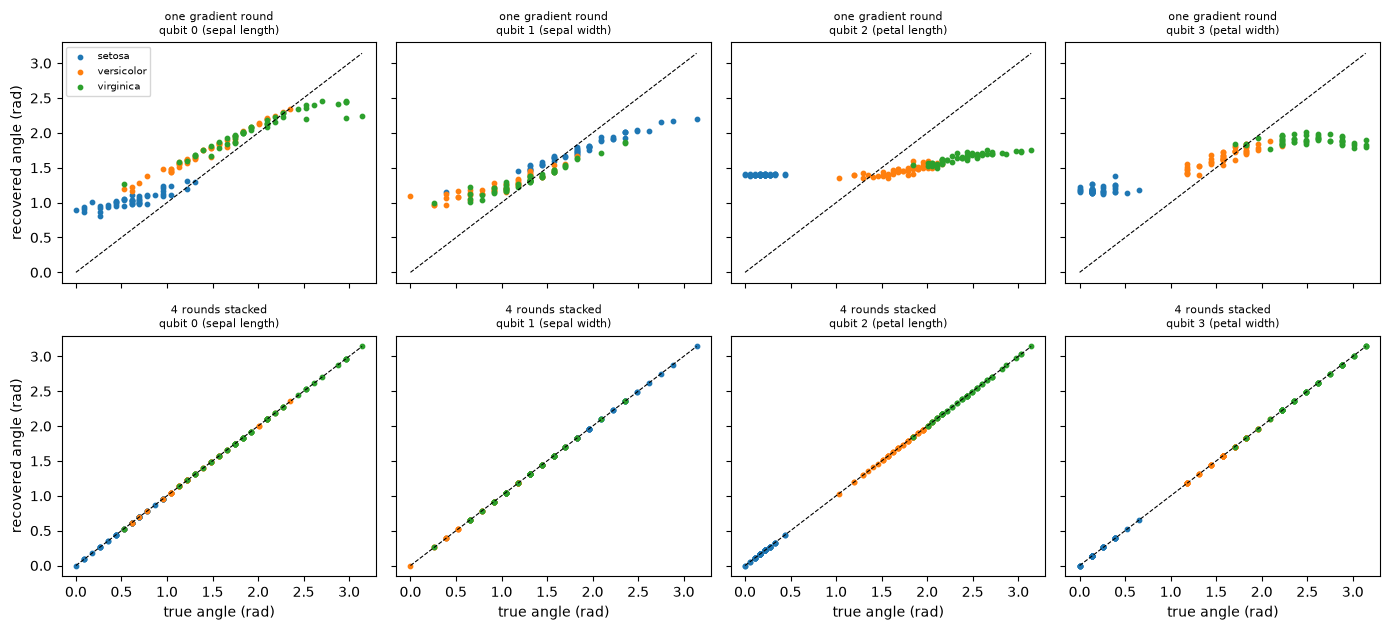

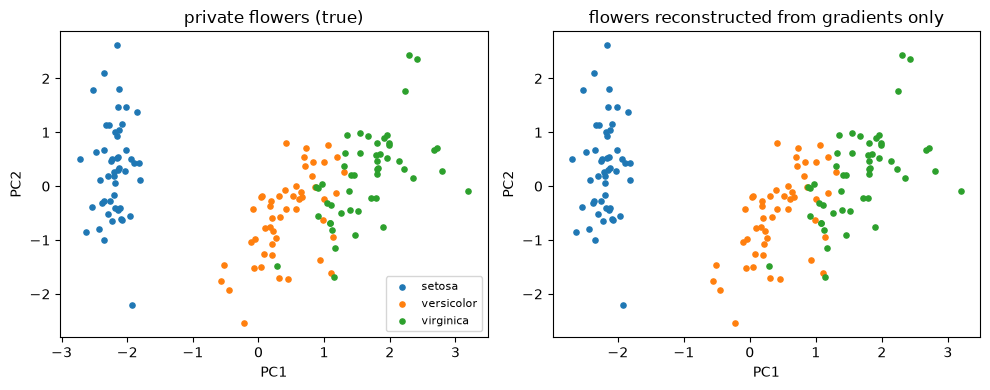

reconstruction error of the encoded measurements (xy_free, full-rank stack): max 1.46e-06 cm, mean 1.22e-08 cm (feature ranges are 2-6 cm); 1 flowers had a feature clipped by the training-range scaling


In [14]:
# Figure: recovered vs true angle for the best-conditioned model (xy_free, full-rank stack) and the one-round attempt
name = "xy_free"
out_full, sm_full = ATTACK[(name, "Rfull", 0)]; out_one, sm_one = ATTACK[(name, "R=1", 0)]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex=True, sharey=True)
for row, (out, title) in enumerate(((out_one, "one gradient round"), (out_full, f"{out_full['A'].shape[0] // MODELS[name].D} rounds stacked"))):
    for j in range(4):
        ax = axes[row, j]
        for k, cname in enumerate(CLASS_NAMES):
            m_ = y_all == k
            ax.scatter(X_ang[m_, j], out["x_rec"][m_, j], s=10, c=COLORS[k], label=cname)
        ax.plot([0, np.pi], [0, np.pi], "k--", lw=0.8)
        ax.set_title(f"{title}\nqubit {j} ({FEATURES[j].replace(' (cm)', '')})", fontsize=8)
        if row == 1: ax.set_xlabel("true angle (rad)")
        if j == 0: ax.set_ylabel("recovered angle (rad)")
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

# Figure: recovered flowers in the PCA plane (real observations coloured by species), original vs reconstructed
X_back = scaler_ang.inverse_transform(out_full["x_rec"])
Zr = pca_vis.transform(std_vis.transform(X_back))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, cname in enumerate(CLASS_NAMES):
    m_ = y_all == k
    ax[0].scatter(Z_pca[m_, 0], Z_pca[m_, 1], c=COLORS[k], s=14, label=cname); ax[1].scatter(Zr[m_, 0], Zr[m_, 1], c=COLORS[k], s=14)
ax[0].set_title("private flowers (true)"); ax[1].set_title("flowers reconstructed from gradients only"); ax[0].legend(fontsize=8)
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()
X_enc = scaler_ang.inverse_transform(X_ang)           # the values that were really encoded (test values outside the training range are clipped to [0, pi])
err_cm = np.abs(X_back - X_enc)
n_clip = int((np.abs(X_enc - X_raw) > 1e-9).any(axis=1).sum())
print(f"reconstruction error of the encoded measurements (xy_free, full-rank stack): max {err_cm.max():.2e} cm, mean {err_cm.mean():.2e} cm (feature ranges are 2-6 cm); {n_clip} flowers had a feature clipped by the training-range scaling")
RES["xy_full_err_cm"] = float(err_cm.max())

## 6. What the weak breach buys the attacker: a classifier trained on recovered snapshots only

The motivation for the weak breach in the paper is that the snapshot can replace the data for *other* learning tasks. We test this with the Iris species: the same stratified split, a standardised RBF-SVM and a random forest are trained on
(a) the raw features (the original data, upper bound), (b) the exact snapshots, (c) the snapshots recovered from the gradients (the attacker never sees $x$), (d) the inputs recovered by Algorithm 3. Test accuracy is reported on the held-out flowers.

mean                   std  \
model                               RandomForest SVC(rbf) RandomForest   
inputs                                                                   
exact snapshot (28 values)                0.9111   0.9111       0.0000   
inputs recovered by Algorithm 3           0.8889   0.9333       0.0000   
raw features (original data)              0.8889   0.9333       0.0000   
recovered snapshot, full-rank stack       0.9111   0.9467       0.0000   
recovered snapshot, one round             0.9156   0.9600       0.0186   

                                              
model                               SVC(rbf)  
inputs                                        
exact snapshot (28 values)            0.0000  
inputs recovered by Algorithm 3       0.0000  
raw features (original data)          0.0000  
recovered snapshot, full-rank stack   0.0253  
recovered snapshot, one round         0.0330

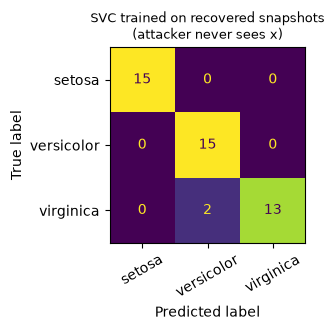

In [15]:
def fit_eval(Ftr, ytr, Fte, yte, kind):
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, random_state=SEED)) if kind == "SVC(rbf)" else RandomForestClassifier(n_estimators=200, random_state=SEED)
    clf.fit(Ftr, ytr); return accuracy_score(yte, clf.predict(Fte))

name = "xy_free"
accs = []
for s in range(N_THETA_SEEDS):
    out_full, _ = ATTACK[(name, "Rfull", s)]; out_one, _ = ATTACK[(name, "R=1", s)]
    sets = {"raw features (original data)": X_ang, "exact snapshot (28 values)": E_TRUE[name], "recovered snapshot, one round": out_one["e_rec"],
            "recovered snapshot, full-rank stack": out_full["e_rec"], "inputs recovered by Algorithm 3": out_full["x_rec"]}
    for lab, F in sets.items():
        for kind in ("SVC(rbf)", "RandomForest"):
            accs.append(dict(seed=s, inputs=lab, model=kind, accuracy=fit_eval(F[idx_train], y_all[idx_train], F[idx_test], y_all[idx_test], kind)))
acc_df = pd.DataFrame(accs)
tab = acc_df.groupby(["inputs", "model"]).accuracy.agg(["mean", "std"]).round(4).unstack("model")
display(tab)
RES["acc"] = acc_df.groupby(["inputs", "model"]).accuracy.mean().to_dict()
cm = confusion_matrix(y_all[idx_test], make_pipeline(StandardScaler(), SVC(random_state=SEED)).fit(ATTACK[(name, "Rfull", 0)][0]["e_rec"][idx_train], y_all[idx_train]).predict(ATTACK[(name, "Rfull", 0)][0]["e_rec"][idx_test]))
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, xticks_rotation=30)
ax.set_title("SVC trained on recovered snapshots\n(attacker never sees x)", fontsize=9); plt.tight_layout(); plt.show()

## 7. Gradient noise (extension, not in the paper)

A real client would estimate gradients with a finite number of shots (parameter shift, $S$ shots gives noise of order $1/\sqrt S$) or add noise as a defence. We add i.i.d. Gaussian noise of standard deviation $\sigma$ to every gradient entry of the
full-rank stack and re-run the attack, showing how fast the linear system amplifies the noise (the condition number of $A$ is reported).

,sigma,angle_MAE_rad,angle_MAE_cm_equiv
0,0.000000e+00,9.932075e-09,1.264591e-08
1,1.000000e-08,1.239588e-06,1.578292e-06
2,1.000000e-06,1.047697e-05,1.333969e-05
3,1.000000e-04,2.562063e-04,3.262119e-04
4,1.000000e-02,1.457362e-02,1.855571e-02
5,1.000000e-01,9.275806e-02,1.181032e-01


condition number of the stacked system A: 10.7; guessing the training mean gives 0.654 rad


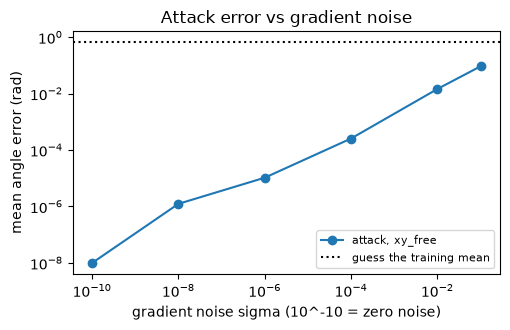

In [16]:
m = MODELS["xy_free"]; plans = PLANS["xy_free"]
out0, _ = ATTACK[("xy_free", "Rfull", 0)]
A, G = out0["A"], out0["G"]
sv = np.linalg.svd(A, compute_uv=False); cond_A = sv[0] / sv[m.dim - 1]
rows = []
rn = np.random.default_rng(SEED)
for sig in NOISE_SIGMAS:
    maes = []
    for rep in range(3):
        Gn = G + rn.normal(0, sig, G.shape)
        e_n = solve_snapshot(A, Gn)
        xr = np.stack([invert_snapshot(p, e_n) for p in plans], axis=1)
        maes.append(np.abs(xr - X_ang).mean())
    rows.append(dict(sigma=sig, angle_MAE_rad=np.mean(maes), angle_MAE_cm_equiv=np.mean(maes) / np.pi * 4.0))
noise_df = pd.DataFrame(rows); display(noise_df)
print(f"condition number of the stacked system A: {cond_A:.1f}; guessing the training mean gives {baseline_mae:.3f} rad")
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.loglog(np.maximum(noise_df.sigma, 1e-10), noise_df.angle_MAE_rad, "o-", label="attack, xy_free")
ax.axhline(baseline_mae, color="k", ls=":", label="guess the training mean"); ax.set_xlabel("gradient noise sigma (10^-10 = zero noise)"); ax.set_ylabel("mean angle error (rad)")
ax.set_title("Attack error vs gradient noise"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
RES["noise_df"] = noise_df

## 8. The privacy-trainability trade-off in numbers: exponential versus polynomial DLA

Theorem 2 says snapshot recovery needs at least $\dim\mathfrak g$ independent equations. For the universal family $\dim\mathfrak g=4^n-1$, so the attacker needs exponentially many gradient entries (more rounds and/or parameters), but with
that budget the attack still works: here we run it on $n=3$ qubits (first three Iris features, $\dim\mathfrak g=63$) with the real PennyLane circuit, and we compare the rank of the stacked system against the number of equations for the polynomial `xy_free` ansatz.

universal n=3: dim DLA = 63 (= 4^3 - 1 = 63 ) | xy_free n=3: dim DLA = 15


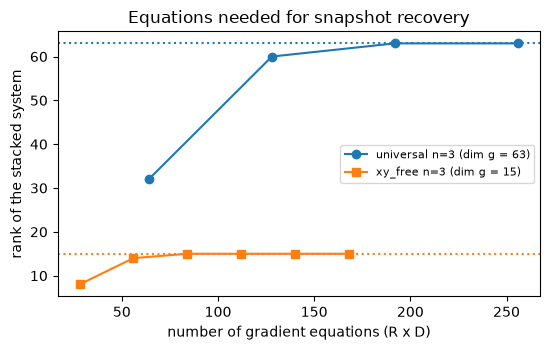

rank reached [universal]: [(64, 32), (128, 60), (192, 63), (256, 63)] 
rank reached [xy_free]: [(28, 8), (56, 14), (84, 15), (112, 15), (140, 15), (168, 15)]


universal n=3: rounds needed for full rank: 3 -> equations: 192


{'rank': 63, 'snap_err_median': 0.0, 'snap_ok': 1.0, 'angle_MAE': 1e-08, 'angle_ok': 1.0, 'failure_qubits': []}


In [17]:
n3 = 3
univ = VQCModel("universal", n3, single(n3, "X") + single(n3, "Z") + chain(n3, "ZZ"), 8, [(1.0, {0: "Z"})])
xy3 = VQCModel("xy_free", n3, chain(n3, "XX") + chain(n3, "YY") + single(n3, "Z"), 4, [(1.0, {0: "Z"})])
print("universal n=3: dim DLA =", univ.dim, "(= 4^3 - 1 =", 4 ** 3 - 1, ") | xy_free n=3: dim DLA =", xy3.dim)

def rank_curve(m, rounds_list, seed):
    th_all = draw_thetas(m, seed, max(rounds_list))
    return [(R * m.D, rank_of(stacked_system(m, th_all[:R]))[0]) for R in rounds_list]
cu = rank_curve(univ, [1, 2, 3, 4], SEED)
cx = rank_curve(xy3, [1, 2, 3, 4, 5, 6], SEED)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.plot(*zip(*cu), "o-", label=f"universal n=3 (dim g = {univ.dim})"); ax.axhline(univ.dim, color="C0", ls=":")
ax.plot(*zip(*cx), "s-", label=f"xy_free n=3 (dim g = {xy3.dim})"); ax.axhline(xy3.dim, color="C1", ls=":")
ax.set_xlabel("number of gradient equations (R x D)"); ax.set_ylabel("rank of the stacked system"); ax.legend(fontsize=8); ax.set_title("Equations needed for snapshot recovery")
plt.tight_layout(); plt.show()
print("rank reached [universal]:", cu, "\nrank reached [xy_free]:", cx)

# attack on the exponential-DLA model with the real circuit, once the system has full rank
R_u, th_u = rounds_needed(univ, SEED)
print("universal n=3: rounds needed for full rank:", R_u, "-> equations:", R_u * univ.D if R_u else None)
X3 = X_ang[:, :3]; sub = np.arange(0, 150, 5)
pl_u = [inversion_plan(univ, j) for j in range(n3)]
out_u = attack_model(univ, pl_u, X3[sub], SEED, R_u, th_u[:R_u])
sm_u = summarise(univ, out_u, X3[sub], univ.snapshot(X3[sub]))
print({k: (round(v, 8) if isinstance(v, float) else v) for k, v in sm_u.items() if k != "per_qubit_MAE"})
RES["univ"] = dict(dim=univ.dim, rounds=R_u, equations=(R_u * univ.D if R_u else None), angle_MAE=sm_u["angle_MAE"], snap_ok=sm_u["snap_ok"],
                   rank_one_round=cu[0][1], rank_curve=cu)

## 9. The paper's own numerical experiments: expectation-value landscapes (Figs. 4 to 8)

Two encoding circuits are compared on $n$ qubits, both measured with $Z\otimes I^{\otimes n-1}$:

* **Fig. 4 circuit**: unknown unitary $V_1$, then a *single* $R_X(x)$ rotation, then an unknown unitary $V_2$ (Haar random). Easy to invert: the expectation is a one-frequency sinusoid for any $n$.
* **Fig. 5 circuit**: $x$ parameterises an SU($2^n$) gate $e^{iHx}$ with a random Hermitian $H$ ($H=(G+G^\dagger)/2$, $G$ complex Gaussian). Its generator has $\sim 4^n$ distinct gap frequencies, so the landscape oscillates ever faster as $n$ grows.

We compute the landscapes exactly (eigendecomposition of $H$), locate the stationary points through the analytic derivative, and reproduce Fig. 6 (distance between stationary points versus $n$), Fig. 7 (1-D landscapes, $n=2..5$) and Fig. 8 (2-D landscapes).
The circuits of Figs. 4 and 5 are drawn from real PennyLane QNodes in the subsection "Quantum Circuit Architecture of the landscape circuits" below and asserted equal to the exact landscape code.

In [18]:
def eig_setup(H, psi0, O):
    lam, V = np.linalg.eigh(H)
    return lam, V.conj().T @ psi0, V.conj().T @ O @ V

def f_df(lam, c, M, xs):
    # f(x) = <psi0| e^{-iHx} O e^{iHx} |psi0>-type expectation of U(x)=e^{iHx}: phi = e^{i lam x} c ; f = phi^dag M phi ; f' = i phi^dag (M L - L M) phi
    phi = np.exp(1j * np.outer(lam, xs)) * c[:, None]
    f = np.real(np.einsum("ag,ab,bg->g", phi.conj(), M, phi))
    Nm = M * lam[None, :] - lam[:, None] * M
    df = np.real(1j * np.einsum("ag,ab,bg->g", phi.conj(), Nm, phi))
    return f, df

def stationary_points(lam, c, M, per_half=GRID_PER_HALF_PERIOD, n_half_periods=100):
    w = max(lam.max() - lam.min(), 1e-9)
    dx = np.pi / (per_half * w); xs = np.arange(0, n_half_periods * np.pi / w, dx)
    f, df = f_df(lam, c, M, xs)
    s = np.where(np.sign(df[:-1]) * np.sign(df[1:]) < 0)[0]
    pts = xs[s] - df[s] * dx / (df[s + 1] - df[s])                 # linear interpolation of the root of f'
    return pts, w

def z_first(n):
    return pauli_op(n, {0: "Z"})

def rand_herm(n, rng):
    G = rng.normal(size=(2 ** n, 2 ** n)) + 1j * rng.normal(size=(2 ** n, 2 ** n))
    return (G + G.conj().T) / 2

# check the analytic derivative against finite differences, and f against a direct expm evaluation
r_ = np.random.default_rng(SEED); H_ = rand_herm(3, r_); e0 = np.zeros(8, complex); e0[0] = 1
lam_, c_, M_ = eig_setup(H_, e0, z_first(3)); xt = np.array([0.37, 1.21])
f_, df_ = f_df(lam_, c_, M_, xt); h = 1e-6
fd = (f_df(lam_, c_, M_, xt + h)[0] - f_df(lam_, c_, M_, xt - h)[0]) / (2 * h)
direct = [np.real((expm(1j * H_ * x) @ e0).conj() @ z_first(3) @ (expm(1j * H_ * x) @ e0)) for x in xt]
print("derivative check:", np.abs(df_ - fd).max(), "| f vs direct expm:", np.abs(f_ - np.array(direct)).max())
assert np.abs(df_ - fd).max() < 1e-6 and np.abs(f_ - np.array(direct)).max() < 1e-10

derivative check: 1.3564749323791148e-10 | f vs direct expm: 1.1657341758564144e-15


,n,r_min_SU,r_min_SU_std,r_mean_SU,omega_max_SU,r_min_RX,r_mean_RX,omega_max_RX
0,2,0.42111,0.27047,0.97721,4.84354,3.14159,3.14159,1.0
1,3,0.12825,0.04993,0.56099,9.02679,3.14159,3.14159,1.0
2,4,0.06902,0.02973,0.35274,14.13403,3.14159,3.14159,1.0
3,5,0.07070,0.03261,0.25143,20.67255,3.14159,3.14159,1.0
4,6,0.03129,0.01939,0.17806,30.49196,3.14159,3.14159,1.0
5,7,0.03184,0.01249,0.12525,43.88798,3.14159,3.14159,1.0
6,8,0.01761,0.00812,0.09070,62.52084,3.14159,3.14159,1.0


Fig. 6 computed in 256.3 s


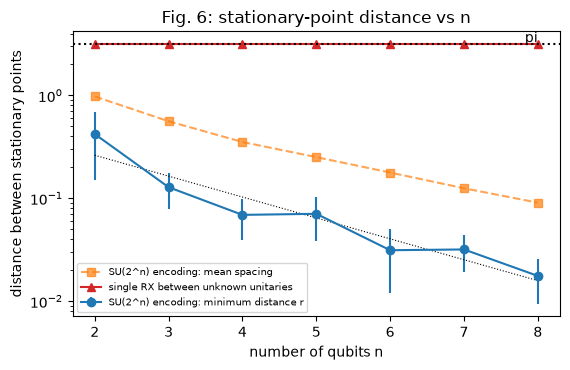

SU(2^n): log2 r_min decreases by 0.68 per qubit (R^2 = 0.913); mean spacing 0.56 per qubit; RX: r_min = [3.1416, 3.1416, 3.1416, 3.1416, 3.1416, 3.1416, 3.1416] (pi = 3.1416)


In [19]:
# Fig. 6: distance r between stationary points of <Z x I...> versus n, for SU(2^n) encoding and for the single-RX encoding between unknown unitaries
def spacing_stats(pts):
    d = np.diff(pts); return d.min(), d.mean()

def su_trial(n, rng):
    H = rand_herm(n, rng); e0 = np.zeros(2 ** n, complex); e0[0] = 1
    pts, w = stationary_points(*eig_setup(H, e0, z_first(n)))
    return (*spacing_stats(pts), w, len(pts))

def rx_trial(n, rng):
    V1, V2 = unitary_group.rvs(2 ** n, random_state=rng), unitary_group.rvs(2 ** n, random_state=rng)
    e0 = np.zeros(2 ** n, complex); e0[0] = 1
    Hx = -0.5 * pauli_op(n, {0: "X"})                                  # RX(x) = exp(-i x X/2) = exp(i H x) with H = -X/2
    pts, w = stationary_points(*eig_setup(Hx, V1 @ e0, V2.conj().T @ z_first(n) @ V2))
    return (*spacing_stats(pts), w, len(pts))

rng6 = np.random.default_rng(SEED)
rows = []
t0 = time.time()
for n in FIG6_NS:
    su = np.array([su_trial(n, rng6) for _ in range(FIG_REPEATS)]); rx = np.array([rx_trial(n, rng6) for _ in range(FIG_REPEATS)])
    rows.append(dict(n=n, r_min_SU=su[:, 0].mean(), r_min_SU_std=su[:, 0].std(), r_mean_SU=su[:, 1].mean(), omega_max_SU=su[:, 2].mean(),
                     r_min_RX=rx[:, 0].mean(), r_mean_RX=rx[:, 1].mean(), omega_max_RX=rx[:, 2].mean()))
fig6 = pd.DataFrame(rows); display(fig6.round(5)); print(f"Fig. 6 computed in {time.time() - t0:.1f} s")
ns = fig6.n.values
slope_min, icpt = np.polyfit(ns, np.log2(fig6.r_min_SU.values), 1)
slope_mean, _ = np.polyfit(ns, np.log2(fig6.r_mean_SU.values), 1)
R2 = np.corrcoef(ns, np.log2(fig6.r_min_SU.values))[0, 1] ** 2
fig, ax = plt.subplots(figsize=(5.8, 3.8))
ax.errorbar(ns, fig6.r_min_SU, yerr=fig6.r_min_SU_std, fmt="o-", label="SU(2^n) encoding: minimum distance r")
ax.plot(ns, fig6.r_mean_SU, "s--", alpha=0.7, label="SU(2^n) encoding: mean spacing")
ax.plot(ns, fig6.r_min_RX, "^-", color="C3", label="single RX between unknown unitaries")
ax.axhline(np.pi, color="k", ls=":"); ax.text(ns[-1], np.pi * 1.05, "pi", ha="right")
ax.plot(ns, 2 ** (icpt + slope_min * ns), "k:", lw=0.8)
ax.set_yscale("log"); ax.set_xlabel("number of qubits n"); ax.set_ylabel("distance between stationary points"); ax.set_title("Fig. 6: stationary-point distance vs n"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"SU(2^n): log2 r_min decreases by {-slope_min:.2f} per qubit (R^2 = {R2:.3f}); mean spacing {-slope_mean:.2f} per qubit; RX: r_min = {fig6.r_min_RX.round(4).tolist()} (pi = {np.pi:.4f})")
RES["fig6"] = dict(ratio=float(fig6.r_min_SU.iloc[0] / fig6.r_min_SU.iloc[-1]), slope_min=float(slope_min), slope_mean=float(slope_mean), R2=float(R2), rx_dev=float(np.abs(fig6.r_min_RX - np.pi).max()),
                   rx_omega=float(fig6.omega_max_RX.mean()))

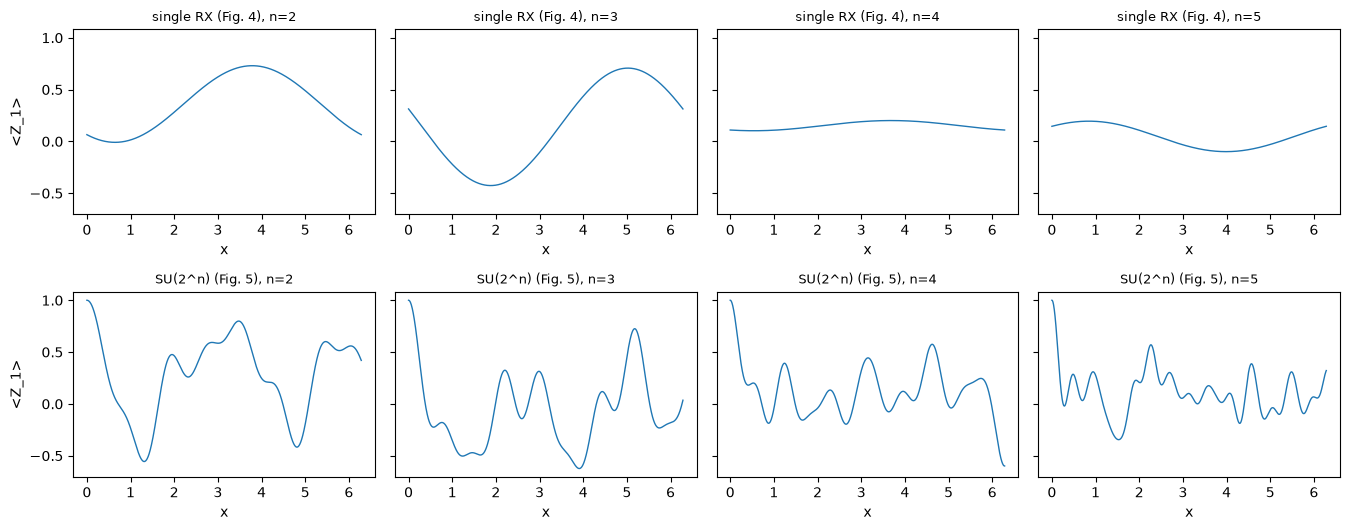

number of stationary points in [0, 2 pi], mean over 10 random draws


encoding,SU(2^n) (Fig. 5),single RX (Fig. 4)
n,,
2,9.9,2.0
3,11.6,2.0
4,14.7,2.0
5,24.4,2.0


In [20]:
# Fig. 7: 1-D landscapes <Z_1>(x) for n = 2..5, single-RX vs SU(2^n)
X7 = np.linspace(0, 2 * np.pi, 1500)
rng7 = np.random.default_rng(SEED + 7)
fig, axes = plt.subplots(2, len(FIG7_NS), figsize=(3.4 * len(FIG7_NS), 5.4), sharey=True)
count_rows = []
for col, n in enumerate(FIG7_NS):
    e0 = np.zeros(2 ** n, complex); e0[0] = 1
    V1, V2 = unitary_group.rvs(2 ** n, random_state=rng7), unitary_group.rvs(2 ** n, random_state=rng7)
    sx = eig_setup(-0.5 * pauli_op(n, {0: "X"}), V1 @ e0, V2.conj().T @ z_first(n) @ V2)
    H = rand_herm(n, rng7); su = eig_setup(H, e0, z_first(n))
    for row, (setup, lab) in enumerate(((sx, "single RX (Fig. 4)"), (su, "SU(2^n) (Fig. 5)"))):
        f, df = f_df(*setup, X7)
        axes[row, col].plot(X7, f, lw=1); axes[row, col].set_title(f"{lab}, n={n}", fontsize=9); axes[row, col].set_xlabel("x")
        pass
    # extrema count averaged over FIG_REPEATS independent random draws (a single draw is noisy)
    cr = {"single RX (Fig. 4)": [], "SU(2^n) (Fig. 5)": []}
    for _ in range(FIG_REPEATS):
        Va, Vb = unitary_group.rvs(2 ** n, random_state=rng7), unitary_group.rvs(2 ** n, random_state=rng7)
        for lab, setup in (("single RX (Fig. 4)", eig_setup(-0.5 * pauli_op(n, {0: "X"}), Va @ e0, Vb.conj().T @ z_first(n) @ Vb)), ("SU(2^n) (Fig. 5)", eig_setup(rand_herm(n, rng7), e0, z_first(n)))):
            _, dfx = f_df(*setup, X7); cr[lab].append(int((np.sign(dfx[:-1]) * np.sign(dfx[1:]) < 0).sum()))
    for lab, v in cr.items(): count_rows.append(dict(n=n, encoding=lab, extrema_in_0_2pi=float(np.mean(v))))
    # the exact-equivalence check with the Fig. 4 / Fig. 5 circuits is done in the circuit section below; store the setups
    globals()[f"_LS_{n}"] = (V1, V2, H, sx, su)
axes[0, 0].set_ylabel("<Z_1>"); axes[1, 0].set_ylabel("<Z_1>")
plt.tight_layout(); plt.show()
cnt = pd.DataFrame(count_rows).pivot(index="n", columns="encoding", values="extrema_in_0_2pi"); print(f"number of stationary points in [0, 2 pi], mean over {FIG_REPEATS} random draws"); display(cnt)
RES["fig7"] = cnt

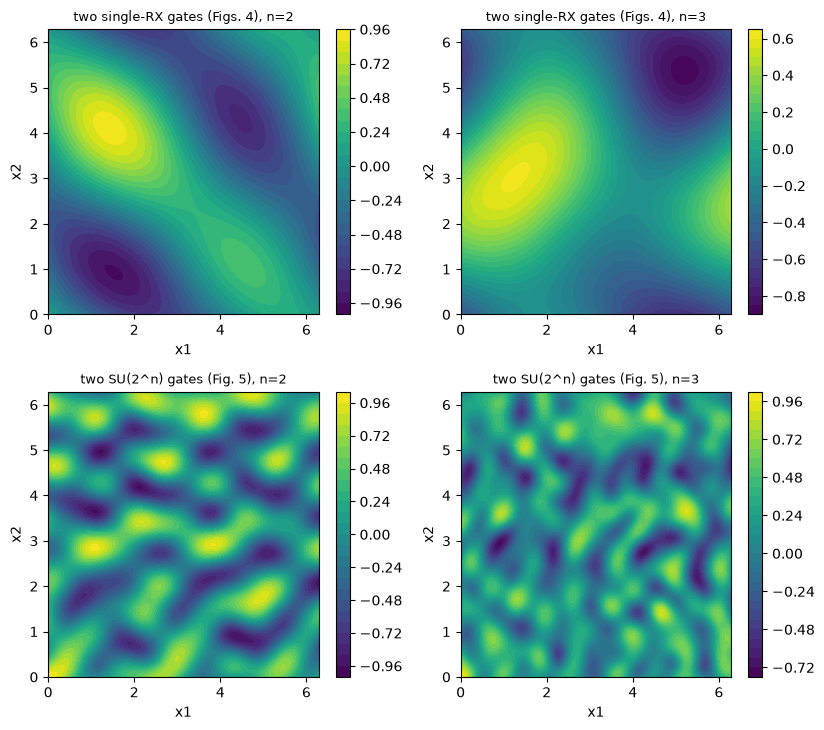

encoding,two SU(2^n) gates (Fig. 5),two single-RX gates (Figs. 4)
n,,
2,27,3
3,61,1


In [21]:
# Fig. 8: 2-D landscapes with two inputs (n = 2, 3). SU: U2(x2) U1(x1); RX: V3 RX(x2) V2 RX(x1) V1 (RX on qubit 1), measure Z_1
G8 = 100; x1 = np.linspace(0, 2 * np.pi, G8); x2 = np.linspace(0, 2 * np.pi, G8)
def rx_state_grid(n, V1, V2, V3, rng):
    e0 = np.zeros(2 ** n, complex); e0[0] = 1
    X0 = pauli_op(n, {0: "X"}); I = np.eye(2 ** n)
    psi1 = np.array([np.cos(a / 2) * I - 1j * np.sin(a / 2) * X0 for a in x1]) @ (V1 @ e0)      # (G, N)
    psi1 = (V2 @ psi1.T)                                                                          # (N, G1)
    Zo = V3.conj().T @ z_first(n) @ V3
    out = np.zeros((G8, G8))
    for i, b in enumerate(x2):
        U = np.cos(b / 2) * I - 1j * np.sin(b / 2) * X0
        ph = U @ psi1
        out[i] = np.real(np.einsum("ag,ab,bg->g", ph.conj(), Zo, ph))
    return out                                                                                    # out[x2_index, x1_index]
def su_state_grid(n, H1, H2):
    e0 = np.zeros(2 ** n, complex); e0[0] = 1
    l1, W1 = np.linalg.eigh(H1); l2, W2 = np.linalg.eigh(H2)
    psi1 = W1 @ (np.exp(1j * np.outer(l1, x1)) * (W1.conj().T @ e0)[:, None])                    # (N, G1)
    Zo = z_first(n); out = np.zeros((G8, G8))
    for i, b in enumerate(x2):
        ph = W2 @ (np.exp(1j * l2 * b)[:, None] * (W2.conj().T @ psi1))
        out[i] = np.real(np.einsum("ag,ab,bg->g", ph.conj(), Zo, ph))
    return out
rng8 = np.random.default_rng(SEED + 8)
fig, axes = plt.subplots(2, len(FIG8_NS), figsize=(4.2 * len(FIG8_NS), 7.4))
fig8_stats = []
for col, n in enumerate(FIG8_NS):
    V1, V2, V3 = [unitary_group.rvs(2 ** n, random_state=rng8) for _ in range(3)]
    Ls = rx_state_grid(n, V1, V2, V3, rng8)
    Lsu = su_state_grid(n, rand_herm(n, rng8), rand_herm(n, rng8))
    for row, (Fz, lab) in enumerate(((Ls, "two single-RX gates (Figs. 4)"), (Lsu, "two SU(2^n) gates (Fig. 5)"))):
        cs = axes[row, col].contourf(x1, x2, Fz, 30, cmap="viridis"); axes[row, col].set_title(f"{lab}, n={n}", fontsize=9)
        axes[row, col].set_xlabel("x1"); axes[row, col].set_ylabel("x2"); plt.colorbar(cs, ax=axes[row, col])
        # roughness: number of local maxima on the grid
        c = Fz[1:-1, 1:-1]; locmax = ((c > Fz[:-2, 1:-1]) & (c > Fz[2:, 1:-1]) & (c > Fz[1:-1, :-2]) & (c > Fz[1:-1, 2:])).sum()
        fig8_stats.append(dict(n=n, encoding=lab, local_maxima_on_grid=int(locmax)))
plt.tight_layout(); plt.show()
fig8_df = pd.DataFrame(fig8_stats).pivot(index="n", columns="encoding", values="local_maxima_on_grid"); display(fig8_df)
RES["fig8"] = fig8_df

### Quantum Circuit Architecture of the landscape circuits (Figs. 4 and 5)

The two encoding circuits of the paper, drawn from real PennyLane QNodes for $n=3$ (the unknown unitaries are the actual random unitaries used in Fig. 7), with qubit count, depth and parameter count. The assertion compares the QNode with the exact
eigendecomposition code that produced the landscapes above (the same code path as Figs. 6 and 7).

max |QNode - exact landscape|  Fig. 4 circuit: 1.6653345369377348e-16  Fig. 5 circuit: 1.7763568394002505e-15


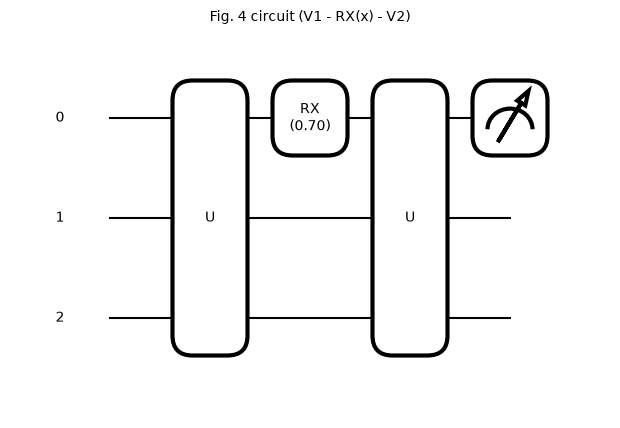

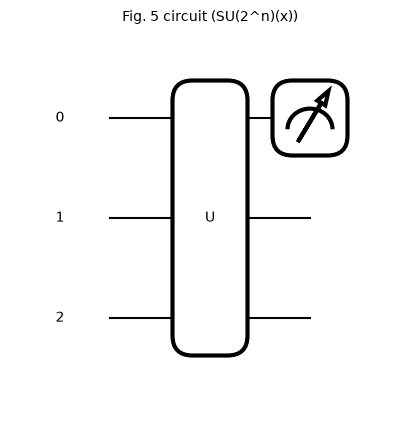

,circuit,qubits,depth,gates,data_inputs,trainable_parameters
0,Fig. 4 circuit (V1 - RX(x) - V2),3,3,3,1,0
1,Fig. 5 circuit (SU(2^n)(x)),3,1,1,1,0


Assumption: the paper does not specify the unitaries; V1, V2 are Haar random (scipy.stats.unitary_group), H is a random Hermitian matrix.


In [22]:
n = 3
V1, V2, H, sx, su = globals()["_LS_3"]
dev3 = qml.device("default.qubit", wires=n)
@qml.qnode(dev3)
def fig4_circuit(x):
    qml.QubitUnitary(V1, wires=range(n))          # unknown arbitrary unitary
    qml.RX(x, wires=0)                            # the single data-dependent rotation
    qml.QubitUnitary(V2, wires=range(n))          # unknown arbitrary unitary
    return qml.expval(qml.PauliZ(0))
@qml.qnode(dev3)
def fig5_circuit(x):
    qml.QubitUnitary(expm(1j * H * x), wires=range(n))     # SU(2^n) gate parameterised by x: U = exp(iHx)
    return qml.expval(qml.PauliZ(0))
xs_chk = np.array([0.4, 1.3, 2.9, 5.1])
f4 = np.array([fig4_circuit(x) for x in xs_chk]); f5 = np.array([fig5_circuit(x) for x in xs_chk])
ref4, ref5 = f_df(*sx, xs_chk)[0], f_df(*su, xs_chk)[0]
print("max |QNode - exact landscape|  Fig. 4 circuit:", np.abs(f4 - ref4).max(), " Fig. 5 circuit:", np.abs(f5 - ref5).max())
assert np.abs(f4 - ref4).max() < 1e-9 and np.abs(f5 - ref5).max() < 1e-9
rows = []
for nm, qn in (("Fig. 4 circuit (V1 - RX(x) - V2)", fig4_circuit), ("Fig. 5 circuit (SU(2^n)(x))", fig5_circuit)):
    fig, ax = qml.draw_mpl(qn, decimals=2, fontsize=10)(0.7); fig.suptitle(nm, y=1.02, fontsize=10); plt.show()
    sp = qml.specs(qn)(0.7)
    rows.append(dict(circuit=nm, qubits=n, depth=sp["resources"].depth, gates=sp["resources"].num_gates, data_inputs=1, trainable_parameters=0))
display(pd.DataFrame(rows))
print("Assumption: the paper does not specify the unitaries; V1, V2 are Haar random (scipy.stats.unitary_group), H is a random Hermitian matrix.")

## 10. Paper versus this notebook: verdict per claim

The paper reports no accuracy-type numbers, so each claim is checked against the quantity it is about. Tolerances: exact (1e-6) for algebraic statements, qualitative (monotone / exponential trend) for the landscape figures.

In [23]:
rk = RES["rank_df"].set_index("model")
def fm(name, tag, col): return att_df[(att_df.model == name) & (att_df.rounds_kind == tag)][col].mean()
FULL, ONE = "full-rank stack", "one round (paper's single system)"
poly_models = ["compound", "xy_free", "tfim_bf"]
full_ok = all(fm(nm, FULL, "snapshot_ok_frac") > 0.99 for nm in poly_models)
one_ok = [fm(nm, ONE, "snapshot_ok_frac") for nm in poly_models]
inv_ok = fm("xy_free", FULL, "angle_ok_frac") > 0.99 and fm("compound", FULL, "angle_ok_frac") > 0.99
fail_expect = (att_df[(att_df.model == "tfim_bf") & (att_df.rounds_kind == FULL)].FAILURE_qubits.apply(lambda l: l == [1, 2]).all())
f6 = RES["fig6"]; f7 = RES["fig7"]; f8 = RES["fig8"]
su_col = [c for c in f7.columns if "SU" in c][0]; rx_col = [c for c in f7.columns if "RX" in c][0]
su_cnt = f7[su_col].values; rx_cnt = f7[rx_col].values
f8su = f8[[c for c in f8.columns if "SU" in c][0]].values; f8rx = f8[[c for c in f8.columns if "RX" in c][0]].values
acc = RES["acc"]
rows = [
 ("Thm 2 / Alg 2: with LASA and a polynomial DLA the snapshot is recovered to epsilon from the gradients",
  "recoverable if D >= dim g (one gradient vector)", f"exact (max error < {EPS_SNAP:g}) on {100*np.mean([fm(nm, FULL, 'snapshot_ok_frac') for nm in poly_models]):.0f}% of flowers with a stack of R rounds; one round: {', '.join(f'{nm} {o*100:.0f}%' for nm, o in zip(poly_models, one_ok))}",
  "reproduced (with stacked rounds)" if full_ok else "not reached"),
 ("Alg 2 as stated: one gradient vector with D >= dim g suffices", "D >= dim g",
  "rank(A) = " + ", ".join(f"{nm} {int(rk.loc[nm, 'rank_A_one_round'])}/{int(rk.loc[nm, 'dim_DLA'])}" for nm in poly_models) + " for a single round", "not reached as stated (rank is limited by the adjoint orbit of O; needs several rounds)"),
 ("Thm 3 / Alg 3: classical snapshot inversion for the Pauli-product encoding (Eq. 30)", "x_j to precision epsilon when iZ_j or iY_j in g",
  f"angle error < {EPS_ANGLE:g} rad for {100*fm('xy_free', FULL, 'angle_ok_frac'):.0f}% (xy_free) and {100*fm('compound', FULL, 'angle_ok_frac'):.0f}% (compound) of inputs; max raw-feature error {RES['xy_full_err_cm']:.1e} cm",
  "reproduced" if inv_ok else "not reached"),
 ("Alg 3 returns FAILURE when neither Z_j, Y_j nor a mix is in g; SVD branch (Eq. 29) works when a mix is in g", "FAILURE / SVD branch",
  f"tfim_bf: FAILURE on exactly the middle qubits [1, 2]: {fail_expect}; tilted-generator SVD branch recovers angles exactly: {RES['svd_branch_ok']}", "reproduced" if (fail_expect and RES['svd_branch_ok']) else "not reached"),
 ("Trade-off: polynomial DLA <-> trainable & recoverable; universal ansatz has exponential DLA (4^n - 1)", "dim g = exp(n) for universal circuits",
  f"universal dim = 4^n - 1 exactly: {RES['univ_exact']}; polynomial families have dims 3n, n(2n-1), (n+1)(2n+1) exactly: {all(RES['poly_exact'].values())}; exponential model needs {RES['univ']['equations']} equations vs {rk.loc['xy_free', 'equations_needed']:.0f} for xy_free (n=3 vs 4)",
  "reproduced" if RES["univ_exact"] else "not reached"),
 ("Fig. 6: distance between stationary points shrinks exponentially with n for the SU(2^n) encoding", "exponential decrease",
  f"log2 r_min falls {-f6['slope_min']:.2f} per qubit (R^2={f6['R2']:.2f}), mean spacing {-f6['slope_mean']:.2f} per qubit, r_min shrinks by a factor {f6['ratio']:.0f} from n={FIG6_NS[0]} to n={FIG6_NS[-1]} (theory: highest frequency grows like 2^(n/2), i.e. 0.5 per qubit)", "reproduced" if (f6['slope_min'] < -0.3 and f6['slope_mean'] < -0.3 and f6['ratio'] > 4) else "not reached"),
 ("Fig. 4/6/7: single-RX encoding between unknown unitaries: r = pi, frequency 1, for every n", "r = pi",
  f"max |r_min - pi| = {f6['rx_dev']:.1e}, highest frequency {f6['rx_omega']:.3f}", "reproduced" if (f6['rx_dev'] < 1e-2 and abs(f6['rx_omega'] - 1) < 1e-6) else "not reached"),
 ("Figs. 7/8: SU(2^n) landscapes oscillate more with n; single-RX landscapes do not", "qualitative",
  f"1-D extrema in [0,2pi] (mean of {FIG_REPEATS} draws): SU {np.round(su_cnt, 1).tolist()} vs RX {np.round(rx_cnt, 1).tolist()}; 2-D local maxima: SU {f8su.tolist()} vs RX {f8rx.tolist()}",
  "reproduced" if (np.all(np.diff(su_cnt) >= 0) and su_cnt[-1] > 5 * rx_cnt.max() and rx_cnt.max() <= 3 and f8su[-1] > f8su[0] and f8su[-1] > f8rx[-1]) else "not reached (check seed)"),
 ("Alg 4 (general local Pauli encodings) and the grid-search lower bound for generic encodings", "polynomial / exponential time", "not implemented (no experiment in the paper)", "cannot be checked"),
 ("Extension (not a paper claim): weak breach is useful, a classifier trained on recovered snapshots matches one trained on exact snapshots", "motivation of Def. 6",
  f"SVC accuracy: raw {acc[('raw features (original data)', 'SVC(rbf)')]:.3f}, exact snapshot {acc[('exact snapshot (28 values)', 'SVC(rbf)')]:.3f}, recovered snapshot (full rank) {acc[('recovered snapshot, full-rank stack', 'SVC(rbf)')]:.3f}, one round {acc[('recovered snapshot, one round', 'SVC(rbf)')]:.3f}", "informative"),
]
verdict_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 200); display(verdict_df)
print("\n".join(f"[{v}] {c}" for c, _, _, v in rows))
print(f"\nTotal notebook run time: {(time.time() - T_START) / 60:.1f} min (FAST_MODE={FAST_MODE})")

,claim,paper,this notebook,verdict
0,Thm 2 / Alg 2: with LASA and a polynomial DLA the snapshot is recovered to epsilon from the gradients,recoverable if D >= dim g (one gradient vector),"exact (max error < 1e-06) on 100% of flowers with a stack of R rounds; one round: compound 0%, xy_free 0%, tfim_bf 0%",reproduced (with stacked rounds)
1,Alg 2 as stated: one gradient vector with D >= dim g suffices,D >= dim g,"rank(A) = compound 8/12, xy_free 12/28, tfim_bf 16/45 for a single round",not reached as stated (rank is limited by the adjoint orbit of O; needs several rounds)
2,Thm 3 / Alg 3: classical snapshot inversion for the Pauli-product encoding (Eq. 30),x_j to precision epsilon when iZ_j or iY_j in g,angle error < 0.001 rad for 100% (xy_free) and 100% (compound) of inputs; max raw-feature error 1.5e-06 cm,reproduced
3,"Alg 3 returns FAILURE when neither Z_j, Y_j nor a mix is in g; SVD branch (Eq. 29) works when a mix is in g",FAILURE / SVD branch,"tfim_bf: FAILURE on exactly the middle qubits [1, 2]: True; tilted-generator SVD branch recovers angles exactly: True",reproduced
4,Trade-off: polynomial DLA <-> trainable & recoverable; universal ansatz has exponential DLA (4^n - 1),dim g = exp(n) for universal circuits,"universal dim = 4^n - 1 exactly: True; polynomial families have dims 3n, n(2n-1), (n+1)(2n+1) exactly: True; exponential model needs 192 equations vs 160 for xy_free (n=3 vs 4)",reproduced
5,Fig. 6: distance between stationary points shrinks exponentially with n for the SU(2^n) encoding,exponential decrease,"log2 r_min falls 0.68 per qubit (R^2=0.91), mean spacing 0.56 per qubit, r_min shrinks by a factor 24 from n=2 to n=8 (theory: highest frequency grows like 2^(n/2), i.e. 0.5 per qubit)",reproduced
6,"Fig. 4/6/7: single-RX encoding between unknown unitaries: r = pi, frequency 1, for every n",r = pi,"max |r_min - pi| = 4.2e-14, highest frequency 1.000",reproduced
7,Figs. 7/8: SU(2^n) landscapes oscillate more with n; single-RX landscapes do not,qualitative,"1-D extrema in [0,2pi] (mean of 10 draws): SU [9.9, 11.6, 14.7, 24.4] vs RX [2.0, 2.0, 2.0, 2.0]; 2-D local maxima: SU [27, 61] vs RX [3, 1]",reproduced
8,Alg 4 (general local Pauli encodings) and the grid-search lower bound for generic encodings,polynomial / exponential time,not implemented (no experiment in the paper),cannot be checked
9,"Extension (not a paper claim): weak breach is useful, a classifier trained on recovered snapshots matches one trained on exact snapshots",motivation of Def. 6,"SVC accuracy: raw 0.933, exact snapshot 0.911, recovered snapshot (full rank) 0.947, one round 0.960",informative


[reproduced (with stacked rounds)] Thm 2 / Alg 2: with LASA and a polynomial DLA the snapshot is recovered to epsilon from the gradients
[not reached as stated (rank is limited by the adjoint orbit of O; needs several rounds)] Alg 2 as stated: one gradient vector with D >= dim g suffices
[reproduced] Thm 3 / Alg 3: classical snapshot inversion for the Pauli-product encoding (Eq. 30)
[reproduced] Alg 3 returns FAILURE when neither Z_j, Y_j nor a mix is in g; SVD branch (Eq. 29) works when a mix is in g
[reproduced] Trade-off: polynomial DLA <-> trainable & recoverable; universal ansatz has exponential DLA (4^n - 1)
[reproduced] Fig. 6: distance between stationary points shrinks exponentially with n for the SU(2^n) encoding
[reproduced] Fig. 4/6/7: single-RX encoding between unknown unitaries: r = pi, frequency 1, for every n
[reproduced] Figs. 7/8: SU(2^n) landscapes oscillate more with n; single-RX landscapes do not
[cannot be checked] Alg 4 (general local Pauli encodings) and the grid

## Reading the paper critically

* **No dataset, qualitative evidence.** The only numerics are landscape plots of random circuits; there is no end-to-end attack experiment, no reported success rate and no comparison with classical gradient inversion. The algebraic claims hold exactly in our run (to machine precision), the landscape claims are reproduced qualitatively; nothing about *practical* attack cost on real data is tested by the paper.
* **Theorem 2 needs a rank condition that "D >= dim g" does not give.** The gradient rows are tangent vectors of the adjoint orbit of $O$ at $c(\theta)$, so a single gradient vector leaves part of the snapshot undetermined even when $D\gg\dim\mathfrak g$ (here 12 of 28 DLA directions for $\mathfrak{so}(8)$ with $O=Z_1$). The attack is repaired by combining a few training rounds, which every federated protocol provides, but the attack's cost statement should read "$R\cdot D\ge\dim\mathfrak g$ and the stacked system must have full rank".
* **Where the attack fails by construction.** Algorithm 3 needs $Z_j$ or $Y_j$ in the DLA. For the TFIM ansatz with boundary fields only the end qubits qualify: privacy of the middle qubits is a *property of the algorithm*, not a guarantee (a snapshot of the whole DLA still leaks them, and a numerical inversion or Algorithm 4 may succeed).
* **Slow Pauli expansion.** All our generators are single Pauli strings with small DLAs, which is the benign case of Definition 9; the notebook can say nothing about circuits where it fails.
* **Noise.** The attack inverts a linear system; a condition number of a few tens makes it robust to shot noise of order $10^{-4}$ but not $10^{-1}$ (Section 7). Quantum noise and differential-privacy noise are future work in the paper.
* **The high-frequency defence.** SU($2^n$) encodings need $\sim 4^n$ gates (no efficient implementation) and the paper itself notes they probably make the model hard to train; the classical Fourier-feature analogue may be equally private.
* **Reproducibility.** The paper's code is "available on request". Random-matrix ensembles, grid resolution and the exact meaning of "average minimum distance" are not specified; we fixed them (table at the top) and the conclusions (exponential decrease vs constant $\pi$) do not depend on these choices.

## Exercises

1. Add a ZZ-coupling ansatz with all-to-all connectivity and a permutation-symmetric observable, run Algorithm 1 for $n=3..6$ and decide whether the DLA is polynomial. Does Algorithm 3 find $Z_j$ for individual qubits?
2. The rank of one gradient round is bounded by the dimension of the adjoint orbit of $O$. Compute this dimension for $O=\sum_j w_jZ_j$ with distinct weights in the `xy_free` ansatz and check that fewer rounds are needed than for $O=Z_1$.
3. Use the MSE loss $L=(y-t)^2$ instead of $y$: the client sends $2(y-t)\,C_j$. Show that the snapshot is then determined up to the unknown scalar $2(y-t)$, and find which additional information the attacker needs.
4. Extend the encoding to $R_X(x_j)R_X(5x_j)$ on two qubits per feature (the Fourier tower map of the paper) and verify that Algorithm 3 still works when applied to one rotation at a time.
5. Replace Iris by another real 4-feature data set (for example the first four PCA components of the breast-cancer data) and compare the angle-recovery error and the classifier accuracy on recovered snapshots.